# B0. read 에서 copy 수까지: WGS read 가 쌓이는 방식과 깊이로 copy 수를 세는 원리

**목표**
- 종양 조직에서 시퀀싱 read 가 만들어지는 과정을 처음부터 따라갑니다: 세포 → DNA 조각 → library → paired-end 시퀀싱 → FASTQ → 정렬(BAM).
- read 가 유전체 위에 **쌓이는(pileup)** 모습을 보고, 쌓인 높이(**깊이, depth**)가 왜 그 자리의 **copy 수**를 세는 눈금이 되는지 이해합니다.
- 이형접합 SNP 에서 read 의 염기를 세면 **BAF** 가 나오는 원리를 봅니다.
- 중복 read, 정렬 품질(MAPQ), 반복 서열, 짝이 어긋난 read 처럼 WGS read 의 특징이 copy 수 계산에 어떻게 끼어드는지 봅니다.
- 마지막으로 COBALT 와 AMBER 가 read 에서 무엇을 만들어 PURPLE 에 넘기는지 봅니다.

**이 노트북이 답하는 질문**: read 가 어떻게 쌓이길래, 쌓인 양으로 copy 수를 셀 수 있나?

B1~B4 는 "깊이 비와 BAF 가 주어졌을 때 PURPLE 이 무엇을 하나"를 다룹니다. 이 B0 은 그 앞, **깊이 비와 BAF 가 read 에서 어떻게 나오나**를 다룹니다.
문장 끝의 `[번호]` 는 맨 아래 **출처** 절의 번호입니다. 그림 속 숫자는 따로 밝히지 않으면 **이 노트북의 장난감 시뮬레이션**입니다.

In [1]:
# 그림 도구 (펼치지 않아도 됩니다). 팔레트: Okabe-Ito, 색의 뜻은 B0~B4 공통
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Rectangle
import purple_mini as pm

COL = dict(tumour="#E69F00", normal="#56B4E9", alleleA="#0072B2", alleleB="#D55E00",
           read="#8C9BAB", read_rev="#B3BFCC", highlight="#CC79A7", ok="#009E73",
           ink="#222222", muted="#6B7280", grid="#E5E7EB", shade="#FFF4E0")


def apply_theme():
    import logging
    logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # 글꼴 대체 경고 숨김
    plt.rcParams.update({
        "font.family": ["Arial", "DejaVu Sans"], "font.size": 10.5,
        "axes.titlesize": 11.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
        "axes.titlepad": 10, "axes.labelsize": 10.5, "axes.labelcolor": COL["ink"],
        "axes.edgecolor": "#9CA3AF", "axes.linewidth": 0.8,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": False, "grid.color": COL["grid"], "grid.linewidth": 0.8,
        "xtick.color": COL["muted"], "ytick.color": COL["muted"],
        "xtick.labelsize": 9.5, "ytick.labelsize": 9.5,
        "legend.frameon": False, "legend.fontsize": 9.5,
        "figure.dpi": 110, "savefig.bbox": "tight", "figure.facecolor": "white",
    })


def panel(ax, letter, title):
    """왼쪽 정렬 'A  제목' 형식의 패널 제목"""
    ax.set_title(f"{letter}   {title}")


def note(ax, x, y, text, **kw):
    """회색 작은 주석"""
    kw.setdefault("fontsize", 9); kw.setdefault("color", COL["muted"])
    ax.text(x, y, text, **kw)


def key_msg(ax, x, y, text, **kw):
    """핵심 메시지: 자주색 굵은 글씨"""
    kw.setdefault("fontsize", 10); kw.setdefault("ha", "left"); kw.setdefault("va", "center")
    ax.text(x, y, text, color=COL["highlight"], fontweight="semibold", **kw)


def bare(ax):
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


def read_bar(ax, x, y, length, h=0.6, color=None, **kw):
    ax.add_patch(FancyBboxPatch((x, y - h / 2), length, h, boxstyle=f"round,pad=0,rounding_size={h * 0.45:.3f}",
                                lw=kw.pop("lw", 0), color=color or COL["read"], **kw))


def arrow(ax, x1, y1, x2, y2, color=None, lw=1.2, style="-|>", **kw):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle=style, color=color or COL["muted"], lw=lw, shrinkA=0, shrinkB=0, **kw))


apply_theme()

# ---- 개념 지도 ----
def draw_concept_map():
    fig, ax = plt.subplots(figsize=(12, 4.3))
    lab, data, tool = "#FFF4E0", "#E8F3FB", "#E6F4EE"
    W, H = 2.05, 1.05
    nodes = [  # (x, y, text, colour, section)
        (1.2, 3.2, "Cells\ntumour + normal", lab, "§1"),
        (3.6, 3.2, "DNA fragments\n~450 bp", lab, "§1"),
        (6.0, 3.2, "Library\nadapters, PCR", lab, "§2"),
        (8.4, 3.2, "Paired-end\nsequencing 2x150", lab, "§2"),
        (10.8, 3.2, "FASTQ\nbases + quality", data, "§3"),
        (10.8, 1.0, "Alignment (BAM)\nposition, MAPQ", data, "§4"),
        (8.4, 1.0, "Pileup\nreads stacked", data, "§5"),
        (6.0, 1.0, "Depth and\nallele counts", data, "§6-8"),
        (3.6, 1.0, "COBALT ratio\nAMBER BAF", tool, "§10"),
        (1.2, 1.0, "PURPLE\npurity, ploidy, CN", tool, "B1-B4"),
    ]
    for x, y, t, c, sec in nodes:
        ax.add_patch(FancyBboxPatch((x - W / 2, y - H / 2), W, H, boxstyle="round,pad=0.02,rounding_size=0.18",
                                    fc=c, ec="#9CA3AF", lw=0.9))
        ax.text(x, y + 0.05, t, ha="center", va="center", fontsize=9.6, color=COL["ink"], linespacing=1.35)
        ax.text(x + W / 2 - 0.08, y + H / 2 - 0.08, sec, ha="right", va="top", fontsize=8.3, color=COL["muted"])
    for i in range(len(nodes) - 1):
        (x1, y1), (x2, y2) = nodes[i][:2], nodes[i + 1][:2]
        if y1 == y2:
            s = np.sign(x2 - x1); arrow(ax, x1 + s * W / 2, y1, x2 - s * W / 2, y2, color="#6B7280")
        else:
            arrow(ax, x1, y1 - H / 2, x2, y2 + H / 2, color="#6B7280")
    note(ax, 0.15, 4.12, "in the lab", fontsize=9.5, color="#B7791F", fontweight="semibold")
    note(ax, 0.15, -0.1, "on the computer", fontsize=9.5, color="#2C6E9B", fontweight="semibold")
    ax.set_xlim(0, 12); ax.set_ylim(-0.35, 4.35); bare(ax)
    plt.show()


# ---- §1 세포에서 DNA 조각까지 ----
def draw_cells_to_fragments(seed=7, purity=0.6):
    rng = np.random.default_rng(seed)
    fig, ax = plt.subplots(1, 3, figsize=(12.5, 4.0), gridspec_kw={"width_ratios": [1, 1.05, 1.35], "wspace": 0.12})
    # A. 세포 섞임
    a = ax[0]
    pts = []
    for _ in range(20000):                                # 겹치지 않게 세포 25개 놓기 (시도 횟수 제한)
        p = rng.uniform(-1, 1, 2)
        if np.hypot(*p) < 0.95 and all(np.hypot(*(p - q)) > 0.25 for q in pts):
            pts.append(p)
        if len(pts) == 25:
            break
    n_t = int(round(purity * len(pts)))
    for i, (x, y) in enumerate(pts):
        c = COL["tumour"] if i < n_t else COL["normal"]
        a.add_patch(Circle((x, y), 0.12, fc=c, ec="white", lw=1.2, alpha=0.95))
    a.set_xlim(-1.15, 1.15); a.set_ylim(-1.35, 1.15); a.set_aspect("equal"); bare(a)
    a.text(-1.05, -1.22, f"tumour cells {n_t}", color="#B7791F", fontsize=9.5, fontweight="semibold")
    a.text(0.25, -1.22, f"normal cells {len(pts) - n_t}", color="#2C6E9B", fontsize=9.5, fontweight="semibold")
    panel(a, "A", f"A biopsy is a mix (purity {purity})")
    # B. 세포마다 copy 수
    a = ax[1]
    for k, (y0, cn, c, lab) in enumerate([(2.2, 3, COL["tumour"], "tumour cell: 3 copies here"),
                                           (0.3, 2, COL["normal"], "normal cell: 2 copies here")]):
        a.add_patch(FancyBboxPatch((0.05, y0 - 0.15), 2.9, 1.45, boxstyle="round,pad=0.02,rounding_size=0.5",
                                   fc="white", ec=c, lw=1.6))
        for j in range(cn):
            a.plot([0.45, 2.55], [y0 + 0.2 + j * 0.38] * 2, lw=6, color=c, solid_capstyle="round", alpha=0.9)
        a.text(1.5, y0 - 0.32, lab, ha="center", va="top", fontsize=9.5, color=COL["ink"])
    a.set_xlim(0, 3); a.set_ylim(-0.4, 3.85); bare(a)
    panel(a, "B", "Each copy is a DNA molecule")
    # C. 잘린 조각
    a = ax[2]
    dna_t, dna_n = purity * 3, (1 - purity) * 2          # 조각 수는 DNA 양에 비례
    n = 60
    origins = rng.random(n) < dna_t / (dna_t + dna_n)
    lens = np.clip(rng.normal(450, 70, n), 250, 650)
    row_end = []
    for o, L in sorted(zip(origins, lens), key=lambda t: -t[1]):
        x0 = rng.uniform(0, 3000 - L)
        r = next((i for i, e in enumerate(row_end) if all(x0 > ee + 40 or x0 + L < ss - 40 for ss, ee in e)), None)
        if r is None:
            row_end.append([]); r = len(row_end) - 1
        row_end[r].append((x0, x0 + L))
        read_bar(a, x0, r, L, h=0.55, color=COL["tumour"] if o else COL["normal"])
    a.set_xlim(0, 3000); a.set_ylim(len(row_end) + 0.3, -0.8); a.set_yticks([])
    a.spines["left"].set_visible(False)
    a.set_xlabel("fragment position in a toy 3 kb stretch (bp)")
    share = origins.mean()
    key_msg(a, 2950, len(row_end) - 1.2, f"{share:.0%} of fragments are tumour DNA\n(expected {dna_t / (dna_t + dna_n):.0%})",
            ha="right", fontsize=9.5)
    panel(a, "C", "Sheared into ~450 bp fragments")
    plt.show()


# ---- §2 library, paired-end, 중복 ----
def draw_paired_end(seed=2):
    rng = np.random.default_rng(seed)
    fig = plt.figure(figsize=(12.5, 5.9))
    gs = fig.add_gridspec(2, 2, height_ratios=[0.85, 1.15], width_ratios=[1, 1.15], hspace=0.45, wspace=0.18)
    # A. 조각 하나와 두 read
    a = fig.add_subplot(gs[0, :])
    frag, rl = 450, 150
    a.add_patch(Rectangle((-40, -0.18), 40, 0.36, color="#4B5563")); a.add_patch(Rectangle((frag, -0.18), 40, 0.36, color="#4B5563"))
    read_bar(a, 0, 0, frag, h=0.36, color="#D1D5DB")
    read_bar(a, 0, 0.75, rl, h=0.42, color=COL["read"]); arrow(a, rl - 10, 0.75, rl + 22, 0.75, color=COL["read"], lw=2)
    read_bar(a, frag - rl, -0.75, rl, h=0.42, color=COL["read"]); arrow(a, frag - rl + 10, -0.75, frag - rl - 22, -0.75, color=COL["read"], lw=2)
    a.text(rl / 2, 1.2, "read 1: first 150 bases", ha="center", fontsize=9.5)
    a.text(frag - rl / 2, -1.2, "read 2: last 150 bases (other strand)", ha="center", va="top", fontsize=9.5)
    a.text(frag / 2, 0.0, "unread middle", ha="center", va="center", fontsize=9, color=COL["muted"])
    a.text(-20, 0.5, "adapter", ha="center", fontsize=8.5, color=COL["muted"]); a.text(frag + 20, 0.5, "adapter", ha="center", fontsize=8.5, color=COL["muted"])
    a.annotate("", xy=(frag, -1.75), xytext=(0, -1.75), arrowprops=dict(arrowstyle="<->", color=COL["highlight"], lw=1.3))
    key_msg(a, frag / 2, -2.1, "insert size = fragment length (here 450 bp)", ha="center", va="top")
    a.set_xlim(-120, 700); a.set_ylim(-2.45, 1.55); bare(a)
    panel(a, "A", "One fragment, read from both ends")
    # B. insert size 분포
    a = fig.add_subplot(gs[1, 0])
    ins = rng.normal(450, 75, 20000)
    a.hist(ins, bins=np.arange(150, 760, 15), color=COL["read"], alpha=0.85, lw=0)
    a.axvline(450, color=COL["ink"], ls=(0, (4, 2)), lw=1.3)
    a.text(600, a.get_ylim()[1] * 0.80, "mean 450\n(dashed line)", fontsize=9.5)
    a.set_xlabel("insert size (bp)"); a.set_ylabel("read pairs"); a.yaxis.grid(True); a.set_axisbelow(True)
    panel(a, "B", "Insert sizes vary around the mean (toy)")
    # C. PCR 중복
    a = fig.add_subplot(gs[1, 1])
    read_bar(a, 0.2, 3.4, 2.2, h=0.36, color="#D1D5DB"); a.text(2.55, 3.4, "one fragment", va="center", fontsize=9.5)
    arrow(a, 1.3, 3.1, 1.3, 2.55, color=COL["muted"]); a.text(1.45, 2.82, "library PCR copies it", va="center", fontsize=9, color=COL["muted"])
    for j in range(3):
        y = 2.1 - j * 0.55
        read_bar(a, 0.2, y, 2.2, h=0.36, color=COL["read"] if j == 0 else COL["read_rev"])
        a.text(2.55, y, "kept" if j == 0 else "flag 0x400 duplicate", va="center", fontsize=9,
               color=COL["ink"] if j == 0 else COL["alleleB"])
    a.annotate("", xy=(0.2, 0.55), xytext=(0.2, 2.35), arrowprops=dict(arrowstyle="-", color=COL["highlight"], lw=1, ls=":"))
    a.annotate("", xy=(2.4, 0.55), xytext=(2.4, 2.35), arrowprops=dict(arrowstyle="-", color=COL["highlight"], lw=1, ls=":"))
    key_msg(a, 0.2, 0.25, "same 5' ends on both reads -> marked duplicate, counted once", fontsize=9.5)
    a.set_xlim(0, 5.2); a.set_ylim(0, 3.75); bare(a)
    panel(a, "C", "PCR duplicates would double-count one molecule")
    plt.show()


# ---- §3 FASTQ 와 염기 품질 ----
def draw_fastq(seed=4, n=150):
    rng = np.random.default_rng(seed)
    q = np.clip(np.round(37 - 6 * (np.arange(n) / n) ** 3 + rng.normal(0, 1.6, n)), 2, 41).astype(int)
    q[rng.choice(n, 3, replace=False)] = rng.integers(8, 16, 3)
    seq = "".join(rng.choice(list("ACGT"), n))
    fig = plt.figure(figsize=(12.5, 6.2))
    gs = fig.add_gridspec(2, 2, height_ratios=[0.9, 1.25], width_ratios=[2.1, 1], hspace=0.5, wspace=0.22)
    a = fig.add_subplot(gs[0, :])
    qual = "".join(chr(v + 33) for v in q)
    lines = ["@read_0001/1", seq[:60] + " ...", "+", qual[:60] + " ..."]
    tags = ["name", "bases", "separator", "quality (one character per base)"]
    for i, (l, t) in enumerate(zip(lines, tags)):
        a.text(0.0, 3 - i, l, family="monospace", fontsize=10, va="center", color=COL["ink"])
        a.text(0.80, 3 - i, t, fontsize=9.5, va="center", color=COL["muted"])
    a.set_xlim(0, 1); a.set_ylim(-0.6, 3.6); bare(a)
    panel(a, "A", "One FASTQ record (usually 4 lines)")
    a = fig.add_subplot(gs[1, 0])
    a.bar(np.arange(1, n + 1), q, width=1.0, color=np.where(q >= 30, COL["read"], COL["alleleB"]), lw=0)
    for lv, lab in [(20, "Q20 = 1 error in 100"), (30, "Q30 = 1 error in 1,000")]:
        a.hlines(lv, 0, n + 1, color=COL["ink"], ls=(0, (4, 2)), lw=1)
        a.text(n + 3, lv, lab, va="center", fontsize=9)
    a.set_xlim(0, n + 48); a.set_ylim(0, 45)
    a.set_xlabel("position in the read (base)"); a.set_ylabel("base quality (Phred Q)")
    panel(a, "B", "Each base has its own quality (toy read)")
    a = fig.add_subplot(gs[1, 1])
    Q = np.arange(0, 51)
    a.plot(Q, 10 ** (-Q / 10), color=COL["read"], lw=2)
    for qq in [10, 20, 30, 40]:
        a.plot(qq, 10 ** (-qq / 10), "o", color=COL["highlight"], ms=6)
        a.text(qq + 1.5, 10 ** (-qq / 10) * 1.6, f"Q{qq}: {10 ** (-qq / 10):g}", fontsize=9)
    a.set_yscale("log"); a.set_xlabel("Phred Q"); a.set_ylabel("chance the base is wrong")
    a.yaxis.grid(True, which="major"); a.set_axisbelow(True)
    panel(a, "C", "Q = -10 log10 P(error)")
    plt.show()
    return q


# ---- §4 정렬, MAPQ, 반복 서열 ----
def draw_alignment():
    fig = plt.figure(figsize=(12.5, 5.0))
    gs = fig.add_gridspec(1, 2, width_ratios=[2.3, 1], wspace=0.22)
    a = fig.add_subplot(gs[0, 0])
    L, rl, h = 10000, 900, 0.13
    reps = [(2200, 3100), (6800, 7700)]
    a.plot([0, L], [0, 0], lw=7, color="#D1D5DB", solid_capstyle="butt")
    for s, e in reps:
        a.plot([s, e], [0, 0], lw=7, color=COL["highlight"], alpha=0.55, solid_capstyle="butt")
        a.text((s + e) / 2, -0.3, "repeat copy", ha="center", va="top", fontsize=9, color=COL["highlight"])
    a.text(0, -0.3, "reference genome", va="top", fontsize=9, color=COL["muted"])
    # 반복이 아닌 곳: 자리 하나 → 높은 MAPQ (read 를 몇 줄로 쌓음)
    uniq = [(150, .45), (700, .75), (1250, .45), (3500, .45), (4100, .75), (4700, .45), (5300, .75),
            (8100, .45), (8650, .75), (9050, .45)]
    for s, y in uniq:
        read_bar(a, s, y, rl, h=h)
    note(a, 9100, 1.02, "unique sequence:\none good place -> high MAPQ\n(e.g. 60)", ha="center", va="bottom", fontsize=9, color=COL["ink"])
    # 반복 서열에서 온 read: 두 곳에 똑같이 맞음
    for s, _ in reps:
        a.add_patch(FancyBboxPatch((s, 0.6 - h / 2), rl, h, boxstyle="round,pad=0,rounding_size=0.06",
                                   fc="white", ec=COL["highlight"], lw=1.4, ls=(0, (3, 2))))
    a.annotate("", xy=(reps[1][0] + rl / 2, 0.75), xytext=(reps[0][0] + rl / 2, 0.75),
               arrowprops=dict(arrowstyle="<->", color=COL["highlight"], lw=1.2, connectionstyle="arc3,rad=-0.3"))
    key_msg(a, (reps[0][0] + reps[1][0]) / 2 + rl / 2, 1.75,
            "one read from the repeat fits both copies equally well\nP(wrong place) >= 0.5  ->  MAPQ <= 3", ha="center", fontsize=9.5)
    a.set_xlim(-200, L + 200); a.set_ylim(-0.65, 2.15); a.set_yticks([]); a.spines["left"].set_visible(False)
    a.set_xlabel("position (bp, toy; reads drawn 900 bp long so they are visible)")
    panel(a, "A", "The aligner places each read; repeats leave it unsure")
    a = fig.add_subplot(gs[0, 1])
    mq = np.array([0, 3, 10, 20, 30, 60])
    p = 10 ** (-mq / 10)
    a.barh(np.arange(len(mq)), -np.log10(p), color=[COL["alleleB"] if m < 10 else COL["read"] for m in mq], height=0.6)
    a.set_yticks(np.arange(len(mq)), [f"MAPQ {m}" for m in mq])
    for i, (m, pp) in enumerate(zip(mq, p)):
        lab = f"P(wrong) = {pp:.2g}" + ("   (BWA-MEM: tie -> 0)" if m == 0 else "")
        a.text(-np.log10(pp) + 0.15, i, lab, va="center", fontsize=9)
    a.axhline(1.5, color=COL["ink"], ls=(0, (4, 2)), lw=1)
    note(a, 3.4, 1.62, "COBALT uses MAPQ >= 10", fontsize=9, color=COL["ink"], va="bottom")
    a.set_xlim(0, 10); a.set_xlabel("-log10 P(wrong place)")
    panel(a, "B", "MAPQ = -10 log10 P(wrong)")
    plt.show()


# ---- §5 pileup 과 깊이 (견본 그림) ----
def pack_rows(starts, length, gap=6):
    """IGV 처럼 겹치지 않게 줄을 배정"""
    row_end, rows = [], []
    for s in starts:
        for i, e in enumerate(row_end):
            if s > e + gap:
                row_end[i] = s + length; rows.append(i); break
        else:
            row_end.append(s + length); rows.append(len(row_end) - 1)
    return np.array(rows)


def draw_reads_to_copies(seed=3, L=2000, read_len=150, base_depth=8):
    rng = np.random.default_rng(seed)
    # 보이는 2 kb 양옆으로 read 길이만큼 더 시뮬레이션해 가장자리 효과를 없앤다
    pos = np.arange(-read_len, L)
    cn = np.where(pos < L // 2, 2, 4)                      # 왼쪽 CN 2, 오른쪽 CN 4
    # 조각은 DNA 양에 비례해 나온다: 자리마다 copy 수에 비례하는 확률로 시작점 뽑기
    n_reads = int(base_depth / 2 * cn.mean() * len(pos) / read_len)
    starts = np.sort(rng.choice(pos, n_reads, p=cn / cn.sum()))
    rows = pack_rows(starts, read_len)
    depth_all = np.zeros(len(pos) + read_len)
    for s in starts:
        depth_all[s + read_len: s + 2 * read_len] += 1
    depth = depth_all[read_len: read_len + L]              # 보이는 0..L 구간

    fig, ax = plt.subplots(3, 1, figsize=(11, 7.6), sharex=True,
                           gridspec_kw={"height_ratios": [1.0, 3.2, 1.6], "hspace": 0.38})
    for a in ax:
        a.axvspan(L // 2, L, color=COL["shade"], zorder=0, lw=0)
    a = ax[0]
    for k in range(4):
        x0 = 0 if k < 2 else L // 2
        a.plot([x0 + 8, L - 8], [k, k], lw=5, solid_capstyle="round",
               color=COL["tumour"] if k >= 2 else COL["ink"], alpha=0.9 if k >= 2 else 0.75)
    a.set_ylim(-0.6, 4.6); a.set_yticks([]); a.tick_params(axis="x", length=0)
    a.spines["left"].set_visible(False)
    note(a, 20, 1.45, "2 copies", fontsize=9.5, color=COL["ink"], va="bottom")
    note(a, L // 2 + 20, 3.45, "4 copies (2 extra = gain)", fontsize=9.5, color="#B7791F", va="bottom")
    panel(a, "A", "DNA copies in the sample")
    a = ax[1]
    for s, r in zip(starts, rows):
        a.add_patch(FancyBboxPatch((s, r + 0.12), read_len, 0.62,
                                   boxstyle="round,pad=0,rounding_size=0.3", lw=0, color=COL["read"]))
    a.set_xlim(0, L); a.tick_params(axis="x", length=0)
    a.set_ylim(rows.max() + 1.2, -0.6)                     # IGV 처럼 위에서부터 쌓기
    a.set_yticks([]); a.spines["left"].set_visible(False)
    a.set_ylabel("aligned reads", color=COL["muted"])
    panel(a, "B", f"Reads pile up where they came from ({read_len} bp each)")
    a = ax[2]
    a.fill_between(np.arange(L), depth, step="mid", color=COL["read"], alpha=0.35, lw=0)
    a.plot(np.arange(L), depth, color=COL["read"], lw=0.8)
    means = []
    for lo, hi in [(0, L // 2), (L // 2, L)]:
        m = depth[lo:hi].mean(); means.append(m)
        a.hlines(m, lo + 30, hi - 30, color=COL["ink"], lw=1.6, ls=(0, (4, 2)))
        a.text(lo + 40, m + 1.0, f"mean depth {m:.1f}", ha="left", va="bottom", fontsize=9.5, color=COL["ink"],
               bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.2), zorder=5)
    xa = L // 2 - 25
    a.annotate("", xy=(xa, means[1]), xytext=(xa, means[0]),
               arrowprops=dict(arrowstyle="<->", color=COL["highlight"], lw=1.4, shrinkA=0, shrinkB=0))
    a.text(xa - 20, means[1] + 3, f"{means[1] / means[0]:.1f}x deeper  ≈  4 copies / 2 copies",
           ha="right", va="bottom", fontsize=10, color=COL["highlight"], fontweight="semibold")
    a.set_ylim(0, depth.max() * 1.25)
    a.yaxis.grid(True); a.set_axisbelow(True)
    a.set_ylabel("depth")
    a.set_xlabel("position in a toy 2 kb region (bp)")
    panel(a, "C", "Depth = number of reads covering each position")
    plt.show()
    return means[1] / means[0]


# ---- §6 깊이는 왜 흔들리나 ----
def simulate_starts(depth, read_len=150, length=2_000_000, seed=0):
    """read 시작점을 균일하게 뿌린다 (기대 깊이 = depth)"""
    rng = np.random.default_rng(seed)
    n = int(depth * length / read_len)
    return np.sort(rng.integers(0, length, n)), length


def per_base_depth(starts, length, read_len=150):
    d = np.zeros(length + read_len + 1)
    np.add.at(d, starts, 1); np.add.at(d, starts + read_len, -1)
    return np.cumsum(d)[:length]


def window_depth(starts, length, w, read_len=150):
    """COBALT 처럼 창마다 '정렬된 염기 수 ÷ 창 길이' = 평균 깊이"""
    d = np.zeros(length + read_len + 1)
    np.add.at(d, starts, 1); np.add.at(d, starts + read_len, -1)
    cov = np.cumsum(d)[:length]
    return cov[: length // w * w].reshape(-1, w).mean(1)


def simulate_pairs(depth, read_len=150, length=2_000_000, insert=450, sd=75, seed=1):
    """짝 read: 조각 하나(insert 평균 450)의 양 끝에서 read 두 개"""
    rng = np.random.default_rng(seed)
    n_frag = int(depth * length / read_len / 2)
    f = rng.integers(0, length - 800, n_frag)
    ins = np.clip(rng.normal(insert, sd, n_frag).astype(int), 2 * read_len, 800)
    return np.sort(np.r_[f, f + ins - read_len]), length


def draw_depth_noise(depth=30, read_len=150):
    starts, length = simulate_starts(depth, read_len)
    pstarts, _ = simulate_pairs(depth, read_len, length)
    d = per_base_depth(starts, length, read_len)[read_len:-read_len]
    sizes = np.array([200, 500, 1000, 2000, 5000, 10000])
    cv_ind, cv_pair = [], []
    for w in sizes:
        x1 = window_depth(starts, length, w, read_len); x2 = window_depth(pstarts, length, w, read_len)
        cv_ind.append(x1.std() / x1.mean()); cv_pair.append(x2.std() / x2.mean())
    cv_ind, cv_pair = np.array(cv_ind), np.array(cv_pair)
    lam = depth * sizes / read_len
    fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.6), gridspec_kw={"wspace": 0.28})
    a = ax[0]
    k = np.arange(0, 61)
    from scipy.stats import poisson
    h = np.bincount(d.astype(int), minlength=61)[:61] / len(d)
    a.bar(k, h, width=1.0, color=COL["read"], alpha=0.8, lw=0, label="simulated bases")
    a.plot(k, poisson.pmf(k, depth), color=COL["ink"], lw=1.6, label=f"Poisson, mean {depth}")
    a.legend(loc="upper right")
    a.set_xlabel("depth at a base"); a.set_ylabel("share of bases"); a.yaxis.grid(True); a.set_axisbelow(True)
    key_msg(a, 1, h.max() * 0.95, f"mean {d.mean():.1f}, SD {d.std():.1f}\n(Poisson SD = {np.sqrt(depth):.1f})", va="top", fontsize=9.5)
    panel(a, "A", f"Per-base depth at {depth}x is wide")
    a = ax[1]
    a.plot(sizes, 1 / np.sqrt(lam), color=COL["ink"], lw=1.4, ls=(0, (4, 2)), label="1 / sqrt(reads per window)")
    a.plot(sizes, cv_ind, "o", color=COL["read"], ms=7, label="independent reads")
    a.plot(sizes, cv_pair, "o", mfc="white", mec=COL["ink"], mew=1.4, ms=7, label="read pairs (insert 450)")
    i = list(sizes).index(1000)
    a.annotate("", xy=(1080, cv_pair[i] * 1.03), xytext=(2300, 0.135),
               arrowprops=dict(arrowstyle="-|>", color=COL["highlight"], lw=1.2))
    key_msg(a, 2400, 0.135, f"1 kb window (~{lam[i]:.0f} reads):\n±{cv_ind[i]:.1%} independent\n±{cv_pair[i]:.1%} in pairs", fontsize=9.5)
    a.set_xscale("log"); a.set_yscale("log")
    a.set_yticks([0.01, 0.02, 0.05, 0.1, 0.2], ["1%", "2%", "5%", "10%", "20%"]); a.minorticks_off()
    a.set_xticks([200, 1000, 10000], ["200", "1,000", "10,000"])
    a.set_xlabel("window size (bp)"); a.set_ylabel("relative noise of window depth (SD / mean)")
    a.legend(loc="lower left"); a.yaxis.grid(True, which="both"); a.set_axisbelow(True)
    panel(a, "B", "Averaging over windows shrinks the noise")
    plt.show()
    return d, sizes, cv_ind, cv_pair, lam


# ---- §7 깊이로 copy 수 세기: 종양 ÷ 정상 ----
def depth_ratio_demo(purity=0.6, cns=(1, 2, 3), n_win=150, normal_reads=200, tumour_reads=400, seed=5):
    """자리 효과 두 가지(GC, 정렬 가능성)가 섞인 장난감 깊이와, 그것을 지우는 두 방법"""
    rng = np.random.default_rng(seed)
    cn = np.repeat(cns, n_win); N = len(cn); x = np.arange(N)
    gc = np.repeat(rng.uniform(0.35, 0.50, N // 3 + 1), 3)[:N] + rng.normal(0, 0.005, N)   # copy 수와 무관한 GC
    gc_t = np.exp(-((gc - 0.42) / 0.10) ** 2)          # 종양 library 의 GC 반응 (한 봉우리)
    gc_n = np.exp(-((gc - 0.44) / 0.12) ** 2)          # 정상 library: 봉우리 자리와 폭이 다름
    mapp = np.ones(N); mapp[200:215] = 0.45            # 정렬이 어려운 자리: 두 시료에 똑같이
    dna = pm.relative_dna(purity, cn)
    t = rng.poisson(tumour_reads * dna / 2 * gc_t / gc_t.mean() * mapp)
    n = rng.poisson(normal_reads * gc_n / gc_n.mean() * mapp)
    ratio_tn = (t / n) / (t.sum() / n.sum())            # (가) 종양 ÷ 정상
    keep = mapp >= 0.85                                 # (나) COBALT 식: 정렬이 어려운 창은 뺌
    bucket = np.round(gc, 2)
    gcr = np.full(N, np.nan)
    for b in np.unique(bucket[keep]):                   # 종양만, 같은 GC 창끼리의 중앙값으로 나눔
        sel = keep & (bucket == b)
        gcr[sel] = t[sel] / np.median(t[sel])
    gcr = gcr / np.nanmean(gcr)                         # 전체 평균 = 1
    level = dna / dna.mean()
    return dict(x=x, cn=cn, dna=dna, gc=gc, t=t, n=n, ratio_tn=ratio_tn, gcr=gcr, keep=keep,
                level=level, purity=purity, n_win=n_win, dip=(200, 215))


def draw_depth_counts_copies(r):
    x, cn, p, nw = r["x"], r["cn"], r["purity"], r["n_win"]
    d0, d1 = r["dip"]
    fig, ax = plt.subplots(4, 1, figsize=(11.5, 10.4), sharex=True,
                           gridspec_kw={"height_ratios": [1.0, 1.3, 1.15, 1.15], "hspace": 0.45})
    for a in ax[1:]:
        a.axvspan(d0, d1, color=COL["highlight"], alpha=0.10, lw=0)
    a = ax[0]
    normal_part = np.full(len(x), 2 * (1 - p)); tumour_part = p * cn
    a.fill_between(x, 0, normal_part, step="mid", color=COL["normal"], alpha=0.75, lw=0)
    a.fill_between(x, normal_part, normal_part + tumour_part, step="mid", color=COL["tumour"], alpha=0.85, lw=0)
    for j, c in enumerate(sorted(set(cn))):
        xm = j * nw + nw / 2; tot = 2 * (1 - p) + p * c
        a.text(xm, tot + 0.12, f"CN {c}: {p}x{c} + {2 * (1 - p):.1f} = {tot:.1f}", ha="center", va="bottom", fontsize=9.5)
    note(a, 4, 0.4, "normal cells: 2 x (1 - p)", color=COL["ink"], fontsize=9, va="center")
    note(a, 4, 1.1, "tumour cells: p x CN", color=COL["ink"], fontsize=9, va="center")
    a.set_ylim(0, 3.3); a.set_ylabel("DNA per cell\n(copies)"); a.tick_params(axis="x", length=0)
    panel(a, "A", f"DNA amount per region (purity {p})")
    a = ax[1]
    a.plot(x, r["t"], ".", color=COL["tumour"], ms=4, label="tumour reads per window")
    a.plot(x, r["n"], ".", color=COL["normal"], ms=4, label="normal reads per window")
    note(a, (d0 + d1) / 2, r["t"].max() * 1.03, "hard-to-map dip\n(same in both)", ha="center", va="bottom", color=COL["highlight"], fontsize=9)
    a.set_ylim(0, r["t"].max() * 1.4); a.set_ylabel("reads per\n1 kb window"); a.tick_params(axis="x", length=0)
    a.legend(loc="upper left", ncol=1); a.yaxis.grid(True); a.set_axisbelow(True)
    panel(a, "B", "Raw counts: copy-number steps + GC waves + a mapping dip")
    for a, key, letter, title, msg in [
        (ax[2], "ratio_tn", "C", "General idea: tumour / matched normal",
         "dip cancels, but GC bias differs between samples -> waves remain"),
        (ax[3], "gcr", "D", "COBALT way: each sample's own GC correction, hard windows dropped",
         "PURPLE fits copy number from this tumour ratio")]:
        a.plot(x, r[key], ".", color=COL["ink"], ms=4)
        a.step(x, r["level"], where="mid", color=COL["highlight"], lw=1.5)
        for j, c in enumerate(sorted(set(cn))):
            v = pm.relative_dna(p, c) / r["dna"].mean()
            a.text(j * nw + 4, v + 0.27, f"expected {v:.2f}", fontsize=9, color=COL["highlight"], zorder=5,
                   bbox=dict(fc="white", ec="none", alpha=0.9, pad=1.5))
        key_msg(a, len(x) / 2, 0.3, msg, ha="center", fontsize=9.5)
        a.set_ylim(0.15, 1.85); a.set_ylabel("ratio\n(genome mean = 1)"); a.yaxis.grid(True); a.set_axisbelow(True)
        panel(a, letter, title)
    ax[2].tick_params(axis="x", length=0)
    ax[3].set_xlabel("1 kb window (toy)")
    plt.show()


# ---- §8 이형접합 SNP 에서 allele 세기 ----
def baf_counts(purity, major, minor, n=30):
    b = pm.expected_baf(purity, major, minor)
    return int(round(b * n)), b


def draw_baf_columns(n=30):
    states = [(1, 1, "1 + 1 balanced"), (2, 1, "2 + 1 gain"), (1, 0, "1 + 0 LOH")]
    fig, ax = plt.subplots(2, 3, figsize=(12, 7.6), gridspec_kw={"hspace": 0.55, "wspace": 0.12})
    for i, p in enumerate([1.0, 0.6]):
        for j, (M, m, lab) in enumerate(states):
            a = ax[i, j]
            nb, b = baf_counts(p, M, m, n)
            for r in range(n):
                y = r * 0.5
                read_bar(a, -3.2, y, 6.4, h=0.36, color="#E5E7EB")
                isB = r < nb
                a.add_patch(Rectangle((-0.35, y - 0.18), 0.7, 0.36, color=COL["alleleB"] if isB else COL["alleleA"], lw=0))
            a.set_xlim(-4.4, 4.4); a.set_ylim(n * 0.5 + 0.2, -0.9); bare(a)
            a.text(0, -0.75, "SNP", ha="center", va="bottom", fontsize=8.5, color=COL["muted"])
            a.text(3.5, nb * 0.25, f"B\n{nb}", ha="center", va="center", fontsize=9.5, color=COL["alleleB"], fontweight="semibold")
            if n - nb:
                a.text(3.5, nb * 0.5 + (n - nb) * 0.25, f"A\n{n - nb}", ha="center", va="center", fontsize=9.5, color=COL["alleleA"], fontweight="semibold")
            a.text(0, n * 0.5 + 0.45, f"BAF = {nb}/{n} = {nb / n:.2f}   (expected {b:.2f})", ha="center", va="top",
                   fontsize=9.6, color=COL["highlight"], fontweight="semibold")
            panel(a, str(3 * i + j + 1), f"{lab}, purity {p}")
    plt.show()


# ---- §9 짝이 어긋난 read 와 갈라진 read ----
def draw_sv_evidence():
    fig = plt.figure(figsize=(12.5, 7.4))
    gs = fig.add_gridspec(2, 1, height_ratios=[1.5, 1], hspace=0.3)
    a = fig.add_subplot(gs[0])
    # 축척을 무시한 도식: 왼쪽 L, 빠진 D, 오른쪽 R
    yT, yR, rl, h = 2.4, 0.0, 0.9, 0.22
    a.plot([0, 4], [yT, yT], lw=9, color="#9CA3AF", solid_capstyle="butt")
    a.plot([4, 8], [yT, yT], lw=9, color="#6B7280", solid_capstyle="butt")
    a.plot([4, 4], [yT - 0.3, yT + 0.3], color=COL["highlight"], lw=2)
    a.text(-0.2, yT, "tumour", ha="right", va="center", fontsize=9.5, color=COL["muted"])
    note(a, 4, yT + 0.42, "junction", ha="center", fontsize=9, color=COL["highlight"])
    a.plot([0, 4], [yR, yR], lw=9, color="#9CA3AF", solid_capstyle="butt")
    a.add_patch(Rectangle((4, yR - 0.09), 3, 0.18, fc="white", ec="#9CA3AF", hatch="////", lw=0.8))
    a.plot([7, 11], [yR, yR], lw=9, color="#6B7280", solid_capstyle="butt")
    a.text(-0.2, yR, "reference", ha="right", va="center", fontsize=9.5, color=COL["muted"])
    note(a, 5.5, yR - 0.42, "deleted in the tumour (3 kb, hatched)", ha="center", va="top", fontsize=9, color=COL["ink"])
    # 어긋난 짝: 종양에서 이음매를 걸친 조각
    f0 = 2.6
    r2 = 7 + (f0 + 2.8 - rl - 4)                          # read 2 가 기준 유전체에 놓이는 자리
    read_bar(a, f0, yT + 0.95, 2.8, h=0.12, color="#D1D5DB")
    read_bar(a, f0, yT + 0.95, rl, h=h, color=COL["alleleA"]); read_bar(a, f0 + 2.8 - rl, yT + 0.95, rl, h=h, color=COL["alleleA"])
    note(a, f0 + 1.4, yT + 1.25, "read pair from one 450 bp fragment", ha="center", fontsize=9, color=COL["alleleA"])
    read_bar(a, f0, yR + 0.75, rl, h=h, color=COL["alleleA"]); read_bar(a, r2, yR + 0.75, rl, h=h, color=COL["alleleA"])
    a.plot([f0 + rl, r2], [yR + 0.75] * 2, color=COL["alleleA"], lw=1.2, ls=(0, (3, 2)))
    for x1, x2 in [(f0 + rl / 2, f0 + rl / 2), (f0 + 2.8 - rl / 2, r2 + rl / 2)]:
        a.plot([x1, x2], [yT + 0.8, yR + 0.9], color="#C7CDD4", lw=0.9)
    note(a, 9.6, yR + 0.75, "mates land 3.45 kb apart\n-> discordant pair", va="center", fontsize=9, color=COL["alleleA"])
    # 갈라진 read
    s0 = 4 - 0.45
    read_bar(a, s0, yT - 0.75, rl, h=h, color=COL["alleleB"])
    note(a, s0 + rl + 0.15, yT - 0.75, "read across the junction", va="center", fontsize=9, color=COL["alleleB"])
    read_bar(a, s0, yR + 0.4, 0.45, h=h, color=COL["alleleB"]); read_bar(a, 7, yR + 0.4, 0.45, h=h, color=COL["alleleB"])
    for x1, x2 in [(s0 + 0.22, s0 + 0.22), (s0 + 0.67, 7.22)]:
        a.plot([x1, x2], [yT - 0.9, yR + 0.55], color="#E8B4A0", lw=0.9)
    note(a, 7.6, yR + 0.4, "split read: primary + supplementary (0x800)", va="center", fontsize=9, color=COL["alleleB"])
    a.set_xlim(-1.4, 12.6); a.set_ylim(-0.9, 3.9); bare(a)
    panel(a, "A", "Reads that straddle a breakpoint mark it exactly (schematic, not to scale)")
    b = fig.add_subplot(gs[1])
    rng = np.random.default_rng(1)
    xw = np.arange(0, 9000, 100)
    true = np.where((xw >= 3000) & (xw < 6000), 1, 2)
    obs = rng.poisson(true * 20) / 20
    b.plot(xw + 50, obs, ".", color=COL["ink"], ms=5)
    b.step(xw, true, where="post", color=COL["highlight"], lw=1.6)
    for xb in (3000, 6000):
        b.axvline(xb, color=COL["alleleB"], lw=1.2, ls=(0, (4, 2)))
    note(b, 3080, 2.6, "SV break = segment edge", color=COL["alleleB"], fontsize=9)
    note(b, 3100, 0.3, "line: true copies (toy)   dots: observed depth per 100 bp, scaled", color=COL["ink"], fontsize=9)
    b.set_ylim(0, 3.0); b.set_xlim(-300, 9300); b.set_yticks([0, 1, 2])
    b.set_ylabel("copies (toy)"); b.set_xlabel("position (bp, toy)"); b.yaxis.grid(True); b.set_axisbelow(True)
    panel(b, "B", "Depth drops between the breaks; SV calls give the exact edges")
    plt.show()


# ---- §10 COBALT 와 AMBER 가 만드는 것 ----
def cobalt_amber_demo(L=12000, w=1000, read_len=150, depth=20, purity=1.0, seed=11, snp_reads=60):
    rng = np.random.default_rng(seed)
    pos = np.arange(-read_len, L)
    cn = np.where(pos < L // 2, 2, 3)
    rel = pm.relative_dna(purity, cn)
    n_t = int(depth * len(pos) / read_len * rel.mean() / 2)
    t_starts = np.sort(rng.choice(pos, n_t, p=rel / rel.sum()))
    n_starts = np.sort(rng.integers(-read_len, L, int(depth * len(pos) / read_len)))

    def coverage(starts):                               # 0..L 자리마다 덮는 read 수
        d = np.zeros(L + 2 * read_len + 1)
        np.add.at(d, starts + read_len, 1); np.add.at(d, starts + 2 * read_len, -1)
        return np.cumsum(d)[read_len: read_len + L]

    t_cov, n_cov = coverage(t_starts), coverage(n_starts)
    t_win = t_cov.reshape(-1, w).mean(1); n_win = n_cov.reshape(-1, w).mean(1)   # 창의 평균 깊이
    het = np.sort(rng.choice(np.arange(300, L - 300), 14, replace=False))
    bafs = []
    for hh in het:
        b = pm.expected_baf(purity, 1 if hh < L // 2 else 2, 1)
        bafs.append(rng.binomial(snp_reads, b) / snp_reads)
    return dict(L=L, w=w, read_len=read_len, starts=t_starts, t_cov=t_cov, t_win=t_win, n_win=n_win,
                t_ratio=t_win / t_win.mean(), n_ratio=n_win / n_win.mean(), het=het, baf=np.array(bafs),
                depth=depth, snp_reads=snp_reads)


def bases_in_window(starts, lo, hi, read_len=150):
    """read 마다 창 [lo, hi) 와 겹치는 염기 수를 더한다 (COBALT 의 'alignment block' 나눠 넣기)"""
    return np.clip(np.minimum(starts + read_len, hi) - np.maximum(starts, lo), 0, None).sum()


def draw_cobalt_amber(r, zoom=(4000, 7000)):
    L, w, rl = r["L"], r["w"], r["read_len"]
    z0, z1 = zoom
    fig = plt.figure(figsize=(11.5, 11.2))
    gs = fig.add_gridspec(4, 1, height_ratios=[2.0, 1.15, 1.4, 1.05], hspace=0.5)
    a0 = fig.add_subplot(gs[0]); a1 = fig.add_subplot(gs[1], sharex=a0)
    a2 = fig.add_subplot(gs[2]); a3 = fig.add_subplot(gs[3], sharex=a2)
    # A. 확대한 3 kb 의 read
    sel = r["starts"][(r["starts"] + rl > z0) & (r["starts"] < z1)]
    rows = pack_rows(sel, rl)
    for a in (a0, a1):
        a.axvspan(L // 2, z1, color=COL["shade"], zorder=0, lw=0)
        for b in range(z0, z1 + 1, w):
            a.axvline(b, color="#9CA3AF", lw=1.0, ls=(0, (3, 2)), zorder=1)
    for s, rr in zip(sel, rows):
        a0.add_patch(FancyBboxPatch((s, rr + 0.18), rl, 0.62, boxstyle="round,pad=0,rounding_size=0.28", lw=0, color=COL["read"]))
    a0.set_xlim(z0, z1); a0.set_ylim(rows.max() + 1.2, -0.8); a0.set_yticks([]); a0.spines["left"].set_visible(False)
    a0.tick_params(axis="x", length=0, labelbottom=False)
    panel(a0, "A", f"Zoom: tumour reads ({r['depth']}x) in three 1 kb windows")
    # B. 자리별 깊이와 창 평균
    xs = np.arange(z0, z1)
    a1.fill_between(xs, r["t_cov"][z0:z1], step="mid", color=COL["read"], alpha=0.35, lw=0)
    a1.plot(xs, r["t_cov"][z0:z1], color=COL["read"], lw=0.8)
    for k, b in enumerate(range(z0, z1, w)):
        m = r["t_win"][b // w]
        a1.hlines(m, b + 20, b + w - 20, color=COL["ink"], lw=1.8)
        a1.text(b + w / 2, m + 3, f"mean = bases / 1000 = {m:.1f}", ha="center", va="bottom", fontsize=9,
                bbox=dict(fc="white", ec="none", alpha=0.85, pad=1.2))
    top = r["t_cov"][z0:z1].max() * 1.6
    for k, b in enumerate(range(z0, z1, w)):
        note(a1, b + w / 2, top * 0.97, f"window {k + 1}" + (" (CN 3)" if b >= L // 2 else " (CN 2)"), ha="center", va="top",
             fontsize=9, color=COL["ink"])
    a1.set_ylim(0, top); a1.set_ylabel("depth"); a1.yaxis.grid(True); a1.set_axisbelow(True)
    a1.set_xlabel("position (bp, zoom)")
    panel(a1, "B", "COBALT window depth = aligned bases in the window / 1,000")
    # C. 12 kb 전체의 창별 비
    cx = np.arange(L // w) * w + w / 2
    a2.plot([z0, z0, z1, z1], [1.66, 1.72, 1.72, 1.66], color=COL["muted"], lw=1)
    note(a2, (z0 + z1) / 2, 1.74, "zoomed in A, B", ha="center", va="bottom", fontsize=8.8)
    a2.axhspan(0.85, 1.15, color=COL["normal"], alpha=0.13, lw=0)
    a2.plot(cx, r["n_ratio"], "s", color=COL["normal"], ms=6)
    note(a2, 150, 1.19, "normal: 0.85-1.15 = DIPLOID (germline status)", color="#2C6E9B", fontsize=9, va="bottom")
    a2.plot(cx, r["t_ratio"], "o", color=COL["ink"], ms=6, zorder=4)
    lv = np.where(cx < L // 2, 2, 3); lv = lv / lv.mean()
    a2.step(np.r_[cx - w / 2, L], np.r_[lv, lv[-1]], where="post", color=COL["highlight"], lw=1.5)
    note(a2, L // 2 + 150, 0.52, "tumour: expected 0.8 -> 1.2 (line); PURPLE fits CN from these", color=COL["ink"], fontsize=9)
    a2.set_ylim(0.4, 1.92); a2.set_ylabel("window ratio\n(sample mean = 1)"); a2.yaxis.grid(True); a2.set_axisbelow(True)
    a2.tick_params(axis="x", length=0, labelbottom=False)
    panel(a2, "C", "Per-window ratios: tumour (dots) and normal (squares)")
    # D. AMBER BAF
    a3.axvspan(L // 2, L, color=COL["shade"], zorder=0, lw=0)
    a3.plot(r["het"], r["baf"], "o", color=COL["alleleB"], ms=7)
    a3.hlines([0.5, 2 / 3], [0, L // 2], [L // 2, L], color=COL["highlight"], lw=1.5)
    note(a3, 150, 0.31, "expected 1/2 for 1 + 1", color=COL["highlight"], fontsize=9, va="center")
    note(a3, L // 2 + 2100, 0.89, "expected 2/3 for 2 + 1", color=COL["highlight"], fontsize=9, va="center")
    a3.set_xlim(0, L); a3.set_ylim(0.25, 0.95); a3.set_ylabel("tumour BAF"); a3.set_xlabel("position in a toy 12 kb region (bp)")
    a3.yaxis.grid(True); a3.set_axisbelow(True)
    panel(a3, "D", f"AMBER: B-allele share at het SNPs ({r['snp_reads']} reads each)")
    plt.show()

## 개념 지도

실험실에서 일어나는 일(위 줄)과 컴퓨터에서 일어나는 일(아래 줄)을 따라가면 PURPLE 입력까지 갑니다. 상자 오른쪽 위의 `§` 는 이 노트북의 절 번호입니다.

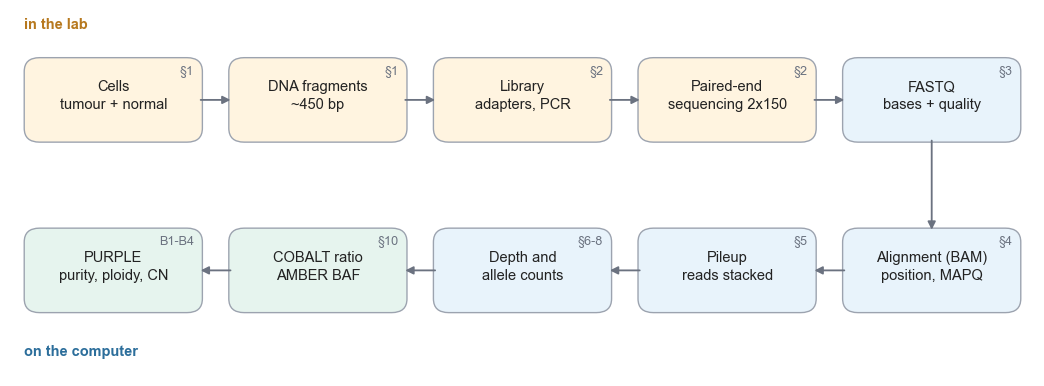

In [2]:
draw_concept_map()

**그림에서 볼 것**
- 위 줄 다섯 상자는 시료에서 FASTQ 파일까지, 아래 줄은 FASTQ 에서 PURPLE 입력까지입니다.
- PURPLE 의 주 입력은 read 그 자체가 아니라 COBALT 의 깊이 비와 AMBER 의 BAF 입니다. 둘 다 "read 를 센 숫자"입니다. 여기에 SV 와 체세포 변이가 더해집니다 [13].
- PURPLE 이 내놓는 purity 는 종양 세포 비율, ploidy 는 종양 세포의 평균 copy 수, CN 은 구간마다의 copy 수입니다(B1 §2·§3).

## 1. 세포에서 DNA 조각까지

**한 줄 정의**: 조직에서 뽑은 DNA 는 모든 세포의 모든 copy 가 섞인 것이고, 이것을 수백 염기 길이의 조각으로 잘라 시퀀싱합니다.

**왜 필요한가**: copy 수를 셀 수 있는 이유가 여기서 시작합니다. 어떤 자리를 3 copy 가진 세포는 그 자리 DNA 를 3 몫 내놓습니다.
조각은 DNA 가 있는 만큼 나오므로, **어느 자리에서 나온 조각이 몇 개인지가 그 자리 DNA 양을 따라갑니다.**
또 종양 조직에는 정상 세포가 섞여 있어(purity, 종양 세포 비율), 조각에도 정상 DNA 가 섞입니다.

**숫자로 따라가기** (purity 0.6, 이 자리를 종양 세포는 3 copy, 정상 세포는 2 copy 가짐)

| | 세포 비율 | 세포 하나의 copy | DNA 몫 | 전체 조각 중 비율 |
|---|---|---|---|---|
| 종양 | 0.6 | 3 | 0.6 × 3 = 1.8 | 1.8 / 2.6 = 69% |
| 정상 | 0.4 | 2 | 0.4 × 2 = 0.8 | 0.8 / 2.6 = 31% |

세포 수로는 60% 가 종양인데, 이 자리에서 나온 조각은 69% 가 종양 DNA 입니다. 종양이 이 자리를 더 많이 가졌기 때문입니다.

실제 예로 Hartwig(HMF)의 전이암 WGS 는 DNA 를 평균 450 염기 조각으로 잘라 library 를 만들었습니다 [1].

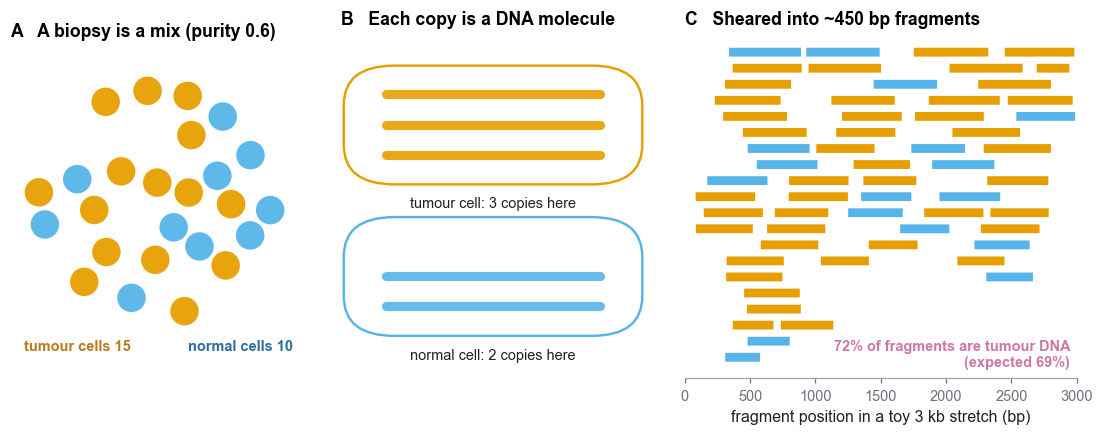

In [3]:
draw_cells_to_fragments(purity=0.6)

**그림에서 볼 것**
- A: 생검 조직은 종양 세포(주황)와 정상 세포(하늘)가 섞여 있습니다. 여기서는 25개 중 15개가 종양(purity 0.6)입니다.
- B: 세포 하나는 이 자리 DNA 를 copy 수만큼 가집니다. 종양 세포 3 copy, 정상 세포 2 copy.
- C: 잘린 조각의 색은 출신(종양/정상)입니다. 조각 60개 중 종양 비율은 표의 기대값 69% 근처입니다(무작위로 뽑았으므로 정확히 같지는 않습니다).

**식과 근거**: 이 자리에서 세포 하나당 나오는 DNA 양은 $p \cdot CN + 2(1-p)$ 입니다. PURPLE 소스 `PurityAdjuster.java` 의 `totalObservations` 와 같은 식이고 [16], 이 노트북은 `purple_mini.relative_dna` 로 씁니다. 조각 길이 450 은 HMF 의 실험 조건입니다 [1].

**직접 바꿔 보기**: 아래 셀에서 `purity` 를 0.2 로 바꿔 보세요. 종양 DNA 비율이 얼마로 떨어지나요?

In [4]:
purity, cn_tumour = 0.6, 3
share = purity * cn_tumour / pm.relative_dna(purity, cn_tumour)
print(f"이 자리 조각 중 종양 DNA 비율: {share:.0%}")
assert abs(share - 1.8 / 2.6) < 1e-12

이 자리 조각 중 종양 DNA 비율: 69%


## 2. library 와 paired-end 시퀀싱

**한 줄 정의**: 조각 양 끝에 기계가 읽을 수 있는 짧은 꼬리(**adapter**)를 붙인 것이 **library** 이고, Illumina 기계는 조각마다 **양 끝에서 각각 읽어** read 두 개(짝, pair)를 만듭니다.

**왜 필요한가**: 양 끝을 읽으면 두 read 가 "같은 조각에서 왔고, 그 사이 거리는 조각 길이(**insert size**)쯤"이라는 정보가 생깁니다.
이 거리 정보가 뒤에서 큰 구조 변이(SV)를 찾는 단서가 됩니다(§9).
또 library 를 만들 때 PCR(DNA 를 복사해 불리는 반응)을 쓰므로, **같은 조각의 복사본이 여러 read 로 읽힐 수 있습니다(중복, duplicate).** 중복을 그대로 세면 한 분자를 여러 번 세는 셈이라 빼야 합니다.

**숫자로 따라가기** (HMF 조건: 조각 평균 450 염기, 2 × 150 읽기 [1])

| | 길이 |
|---|---|
| 조각(insert) | 450 |
| read 1 (앞에서) | 150 |
| read 2 (뒤에서, 반대 가닥) | 150 |
| 가운데 읽지 않은 부분 | 450 − 300 = 150 |

Illumina 방식은 유리판 위에 붙인 조각 하나하나를 그 자리에서 복사해 덩어리(cluster)를 만든 뒤 읽고, 짝 읽기(paired read)를 지원합니다 [2].
library PCR 은 GC 가 극단적인 자리를 덜 불리는 편향의 주된 원인으로도 알려져 있습니다 [3] (B1 §5 의 GC 편향).

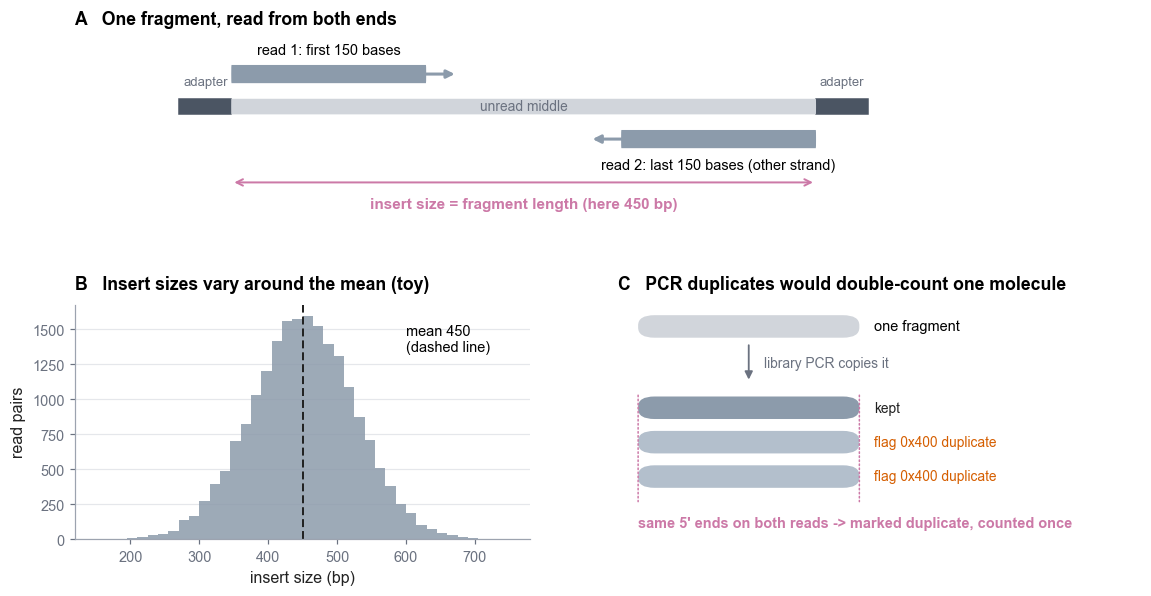

In [5]:
draw_paired_end()

**그림에서 볼 것**
- A: 회색 막대가 조각, 양 끝 진한 칸이 adapter 입니다. read 1 은 왼쪽 끝에서 오른쪽으로, read 2 는 오른쪽 끝에서 왼쪽으로(반대 가닥) 150 염기씩 읽습니다. 두 read 바깥 끝 사이 거리(자주 화살표)가 insert size 입니다.
- B: 조각 길이는 하나로 정해지지 않고 평균 근처에 퍼집니다(장난감 분포). 이 분포에서 크게 벗어난 짝은 이상한 짝입니다(§9).
- C: PCR 이 한 조각을 여럿으로 복사하면 같은 자리에 똑같이 놓이는 read 짝이 여러 개 생깁니다. 중복 표시 도구는 보통 두 read 의 5' 끝 자리를 비교해 같으면 같은 분자의 복사본으로 봅니다(Picard MarkDuplicates [17]).
  이런 read 에 중복 표시(SAM flag `0x400`, "PCR or optical duplicate")를 붙이고 [6], 셀 때는 하나만 셉니다.

**식과 근거**: HMF 는 DNA 를 평균 450 염기로 잘라 TruSeq Nano library 를 만들고, HiSeq X 에서 2 × 150 짝으로 읽었으며, 정렬 뒤 중복을 표시해 걸렀습니다 [1].

**직접 바꿔 보기**: 조각이 250 염기라면 2 × 150 짝은 어떻게 될까요? 아래 셀이 계산합니다.

In [6]:
insert, read_len = 250, 150
middle = insert - 2 * read_len
print("가운데 읽지 않은 부분:", middle, "→ 음수면 두 read 가 서로 겹쳐 같은 염기를 두 번 읽음")

가운데 읽지 않은 부분: -50 → 음수면 두 read 가 서로 겹쳐 같은 염기를 두 번 읽음


## 3. FASTQ: 염기와 염기 품질

**한 줄 정의**: 시퀀서가 내놓는 read 파일(FASTQ)은 read 하나를 보통 네 줄로 적습니다: 이름, 염기, 구분자 `+`, 그리고 **염기마다 하나씩 품질 글자**. (서열 줄을 여러 줄로 나눠 적을 수도 있지만 흔히 한 줄로 씁니다 [4].)

**왜 필요한가**: 기계도 염기를 틀리게 읽습니다. 품질 점수는 "이 염기가 틀렸을 확률"을 숫자로 알려 주므로, 품질이 낮은 염기는 BAF(§8: 이형접합 자리에서 한쪽 염기가 차지하는 비율)를 셀 때 빼고 셀 수 있습니다.
AMBER 는 품질 13 미만인 염기를 세지 않습니다 [12].

**숫자로 따라가기**: 품질 점수 $Q$ 와 틀릴 확률 $P$ 는 $Q = -10 \log_{10} P$ 의 관계입니다.

| Q | 틀릴 확률 | 뜻 |
|---|---|---|
| 10 | 0.1 | 10개에 1개 틀림 |
| 20 | 0.01 | 100개에 1개 |
| 30 | 0.001 | 1,000개에 1개 |
| 40 | 0.0001 | 10,000개에 1개 |

FASTQ 는 이 숫자를 글자 하나로 적습니다. 표준(Sanger) FASTQ 는 Q 에 33 을 더한 ASCII 글자를 쓰므로, Q 30 은 `?`(ASCII 63)입니다 [4].

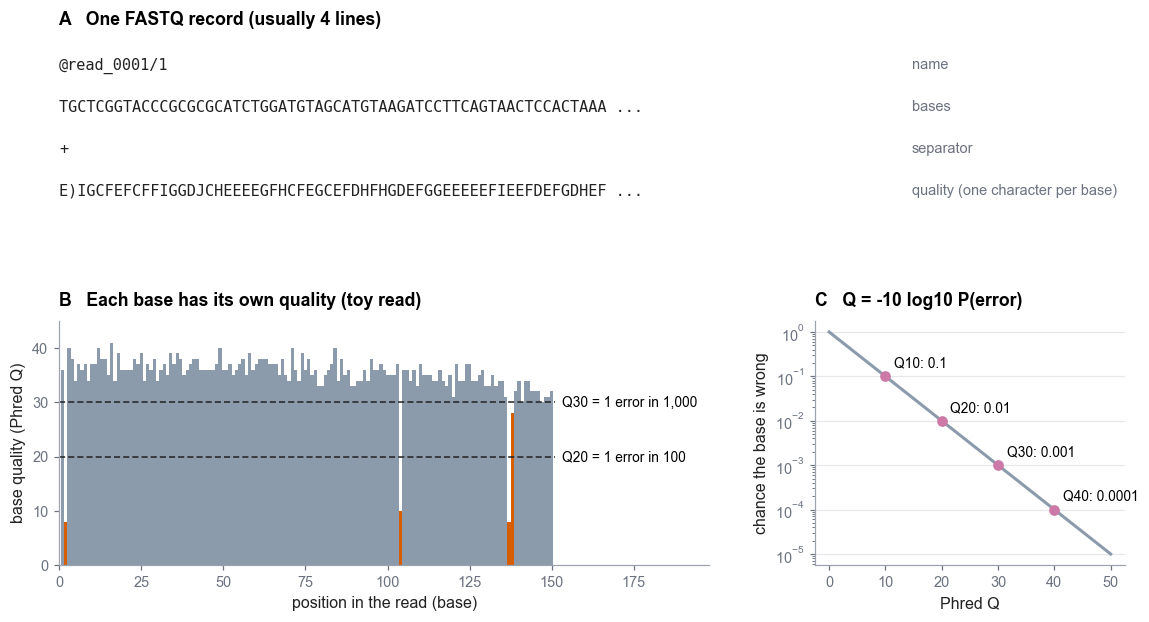

In [7]:
q = draw_fastq()

**그림에서 볼 것**
- A: read 하나가 (보통) 네 줄입니다. 넷째 줄 글자 하나하나가 둘째 줄 염기 하나하나의 품질입니다(앞 60 글자만 보임).
- B: 장난감 read 의 염기별 품질입니다. 대부분 Q 30 위(회청)이고, 빨간 막대는 Q 30 아래입니다. 끝으로 갈수록 품질이 떨어지는 모양은 이 그림의 가정입니다.
- C: Q 가 10 오를 때마다 틀릴 확률이 10배 줄어듭니다(세로축이 로그 눈금이라 직선).

**식과 근거**: 품질 점수는 phred 프로그램이 염기마다 틀릴 확률을 추정한 데서 시작했습니다 [5]. Sanger FASTQ 는 ASCII 33~126 으로 PHRED 0~93 을 적고, 이는 틀릴 확률 1.0 에서 $10^{-9.3}$ 까지에 해당합니다 [4]. 이 대응이 바로 $P = 10^{-Q/10}$ 입니다.

**직접 바꿔 보기**: 150 염기가 모두 Q 30 이면 read 하나에 평균 몇 개가 틀릴까요?

In [8]:
Q = 30
expected_errors = 150 * 10 ** (-Q / 10)
print(f"Q{Q} 150 염기 read 의 평균 오류 수: {expected_errors:.2f}")
assert chr(30 + 33) == "?" and np.isclose(expected_errors, 0.15)

Q30 150 염기 read 의 평균 오류 수: 0.15


## 4. 정렬(alignment)과 BAM: read 를 유전체 위 제자리에 놓기

**한 줄 정의**: 정렬 프로그램(예: BWA-MEM)이 read 마다 기준 유전체(reference)의 어느 자리에서 왔는지 찾아 적고, 그 결과를 BAM 파일에 담습니다.

**왜 필요한가**: read 를 제자리에 놓아야 "이 자리에 read 가 몇 개 쌓였나"를 셀 수 있습니다.
그런데 유전체에는 똑같거나 거의 같은 서열이 여러 곳에 있습니다(**반복 서열**). 그런 곳에서 온 read 는 어디서 왔는지 확신할 수 없어, 잘못된 자리에 쌓일 수 있습니다.
그래서 read 마다 **정렬 품질(MAPQ)**, 즉 "이 자리가 틀렸을 확률"을 함께 적습니다.

**숫자로 따라가기**: MAPQ 도 $-10 \log_{10} P(\text{틀린 자리})$ 입니다 [6].

| 상황 | 틀린 자리일 확률 | MAPQ |
|---|---|---|
| 똑같이 잘 맞는 자리가 두 곳 | 0.5 이상 | 식으로는 3 이하, 실제 BWA-MEM 은 0 [19] |
| 열에 하나 틀림 | 0.1 | 10 |
| 백만에 하나 | $10^{-6}$ | 60 |

COBALT 는 MAPQ 10 이상인 read 만 셉니다 [10].

**BAM 의 표시(flag)** 몇 가지 [6]:

| flag | 뜻 | COBALT 가 셀 때 [10] |
|---|---|---|
| `0x4` | 정렬 안 됨(unmapped) | 뺌 |
| `0x100` | 보조 자리(secondary): 같은 read 의 다른 후보 자리 | 뺌 |
| `0x400` | 중복(PCR or optical duplicate) | 뺌 |
| `0x800` | 추가 조각(supplementary): read 가 두 동강으로 나뉘어 정렬될 때 대표가 아닌 쪽 | 뺌 |

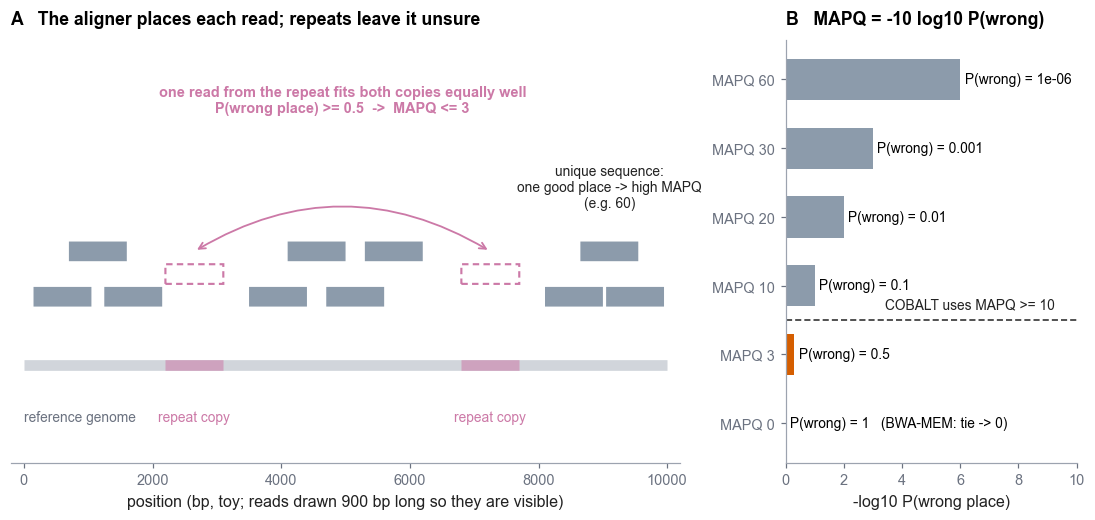

In [9]:
draw_alignment()

**그림에서 볼 것**
- A: 회색 줄이 기준 유전체, 자주색 칸 두 개는 서로 같은 서열(반복 서열)입니다. 반복이 아닌 곳의 read 는 자리가 하나라 MAPQ 가 높습니다(예시 값 60).
  반복 서열에서 온 read(점선 테두리)는 두 곳에 똑같이 잘 맞아, 틀린 자리일 확률이 최소 0.5 이므로 식으로는 MAPQ 3 이하입니다.
  실제 BWA-MEM 은 가장 좋은 점수와 두 번째 점수가 같으면 MAPQ 를 0 으로 줍니다 [19].
- B: MAPQ 를 틀릴 확률로 바꾼 막대그래프입니다. 점선 아래(MAPQ 10 미만, 빨강)는 COBALT 가 세지 않습니다.

**식과 근거**: SAM 형식 명세는 MAPQ 를 "−10 log10 Pr{mapping position is wrong}" 로 정의하고, 여러 자리에 맞는 경우는 주로 반복 서열 때문이며 read 가 길수록 드물다고 적습니다 [6].
BWA-MEM 은 짝 read 를 지원하고, 한 read 를 두 조각으로 나눠 정렬하는 chimeric 정렬도 합니다 [7]. HMF 도 BWA-mem 으로 정렬했습니다 [1].

**직접 바꿔 보기**: 똑같이 맞는 자리가 세 곳이면 MAPQ 는 최대 얼마일까요?

In [10]:
for n_places in [2, 3, 10]:
    p_wrong = 1 - 1 / n_places
    print(f"똑같은 자리 {n_places}곳 → P(틀림) ≥ {p_wrong:.2f} → MAPQ ≤ {-10 * np.log10(p_wrong):.1f}")

똑같은 자리 2곳 → P(틀림) ≥ 0.50 → MAPQ ≤ 3.0
똑같은 자리 3곳 → P(틀림) ≥ 0.67 → MAPQ ≤ 1.8
똑같은 자리 10곳 → P(틀림) ≥ 0.90 → MAPQ ≤ 0.5


## 5. pileup 과 깊이: read 가 쌓인 높이

**한 줄 정의**: 정렬된 read 를 유전체 위에 겹쳐 쌓은 것을 **pileup** 이라 하고, 한 자리를 덮는 read 의 수를 그 자리의 **깊이(depth, coverage)** 라고 합니다.

**왜 필요한가**: §1 에서 본 것처럼 조각은 DNA 양에 비례해 나옵니다. 정렬은 각 조각을 원래 자리에 돌려놓으므로, **DNA 가 두 배인 자리에는 read 도 두 배로 쌓입니다.** 이것이 깊이로 copy 수를 세는 원리의 전부입니다.

**숫자로 따라가기**: 평균 깊이는 "읽은 염기 총량 ÷ 유전체 길이"입니다. Lander–Waterman 식으로 $C = L N / G$ ($L$ read 길이, $N$ read 수, $G$ 유전체 길이) [8][9].

| 무엇 | 값 |
|---|---|
| 유전체 길이 $G$ | 약 31억 염기 (GRCh38 전체 3,099,750,718 bp [15]) |
| 목표 깊이 $C$ | 30x |
| read 길이 $L$ | 150 |
| 필요한 read 수 $N = C G / L$ | 30 × 3.1×10⁹ / 150 ≈ 6.2억 read = 약 3.1억 짝 |

GRCh38 의 3,099,750,718 은 chrY, 위치가 정해지지 않은 조각, 알 수 없는 염기(N) 구간까지 모두 더한 값입니다 [15].
[8] 은 $G$ 를 반수체 유전체 길이로 정의하고 예시에 $3 \times 10^9$ 를 씁니다. 그 값이면 6.0억 read 로, "약 6억 read, 3억 짝"이라는 답은 같습니다.

In [11]:
G, C, L = 3_099_750_718, 30, 150
N = C * G / L
print(f"30x 에 필요한 read {N / 1e8:.1f}억 개 = 짝 {N / 2 / 1e8:.2f}억 개")
assert 6.1e8 < N < 6.3e8

30x 에 필요한 read 6.2억 개 = 짝 3.10억 개


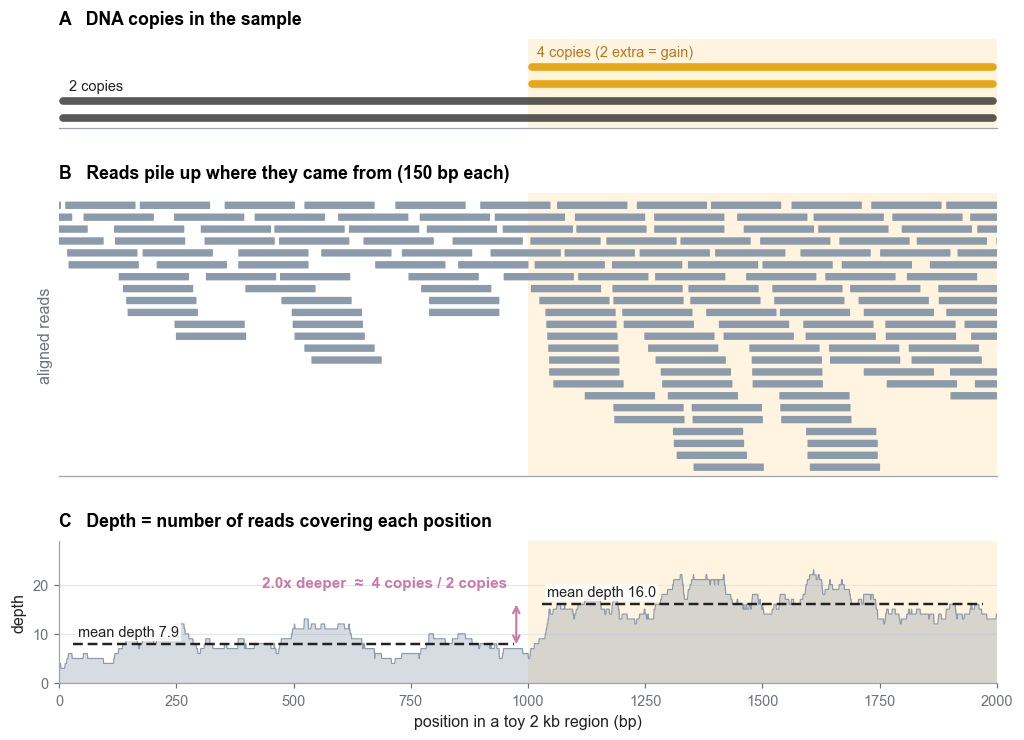

In [12]:
ratio = draw_reads_to_copies()

**그림에서 볼 것**
- A: 장난감 2 kb 구간의 왼쪽 절반은 2 copy, 오른쪽 절반(옅은 주황 배경)은 4 copy 입니다(2 copy 가 더 생긴 증폭).
- B: 150 염기 read 들이 자기가 온 자리에 쌓였습니다. 오른쪽에 read 가 더 빽빽하고 더 높이 쌓입니다.
- C: 깊이를 자리마다 세면 왼쪽 평균은 약 8, 오른쪽은 약 16 입니다. **깊이 비 약 2 = copy 비 4/2** 입니다(자주 화살표).

**식과 근거**: 깊이는 DNA 양에 비례하므로 두 구간의 깊이 비는 DNA 양의 비와 같습니다. 순수한 종양이면 copy 수의 비 그대로입니다. 정상 세포가 섞이면 §7 처럼 $p \cdot CN + 2(1-p)$ 의 비가 됩니다.

**직접 바꿔 보기**: `draw_reads_to_copies(base_depth=30)` 으로 깊이를 올려 보세요. 비가 2 에 더 가까워지나요? (`seed` 를 바꿔 여러 번 해 보면 좋습니다.)

In [13]:
assert 1.6 < ratio < 2.4

## 6. 깊이는 왜 흔들리나: 무작위 뽑기의 잡음

**한 줄 정의**: 조각은 무작위로 뽑히므로, copy 수가 같은 자리끼리도 깊이가 들쭉날쭉합니다. read 가 서로 독립이면 이 흔들림은 대략 **Poisson 분포**(평균만큼 무작위로 일어나는 사건 수의 분포)를 따릅니다.

**왜 필요한가**: 깊이 한 자리만 보면 copy 수를 가를 수 없습니다. 30x 에서 한 염기의 깊이는 표준편차가 약 5.5 라, 2 copy 와 3 copy(깊이 30 대 45)도 자주 겹칩니다.
그래서 COBALT 는 **1 kb 창(window)** 마다 평균 깊이(창에 정렬된 염기 수 ÷ 1,000)를 씁니다 [11][18]. 넓게 평균할수록 상대 잡음이 대략 $1/\sqrt{\text{창의 read 수}}$ 꼴로 줄어듭니다.

**숫자로 따라가기** (30x, 150 염기 read, read 가 서로 독립이라고 가정)

| 창 크기 | 창 하나의 평균 read 수 $\lambda = 30 \times w / 150$ | 상대 잡음 $1/\sqrt{\lambda}$ |
|---|---|---|
| 200 bp | 40 | 16% |
| 1 kb | 200 | 7.1% |
| 10 kb | 2,000 | 2.2% |

실제 read 는 짝으로 옵니다. 한 조각의 두 read(insert 450)는 같은 1 kb 창에 함께 떨어지는 일이 많아 둘씩 묶여 움직이므로, 독립인 경우보다 더 흔들립니다.
이 노트북의 시뮬레이션(30x, 2 × 150, insert 평균 450)에서는 1 kb 창 잡음이 약 ±9% 입니다(아래 그림 B).

실제 데이터는 여기에 자리 효과가 더해져 더 흔들립니다. GC 함량(B1 §5)과 **mappability**(정렬 가능성: 그 자리 read 가 한 곳으로만 정렬될 수 있는 정도, §4·§9) 때문입니다.
COBALT v2.0 이 GC 0.2~0.6 밖이거나 평균 mappability 0.85 미만인 창을 빼는 것도 이 때문입니다 [10].

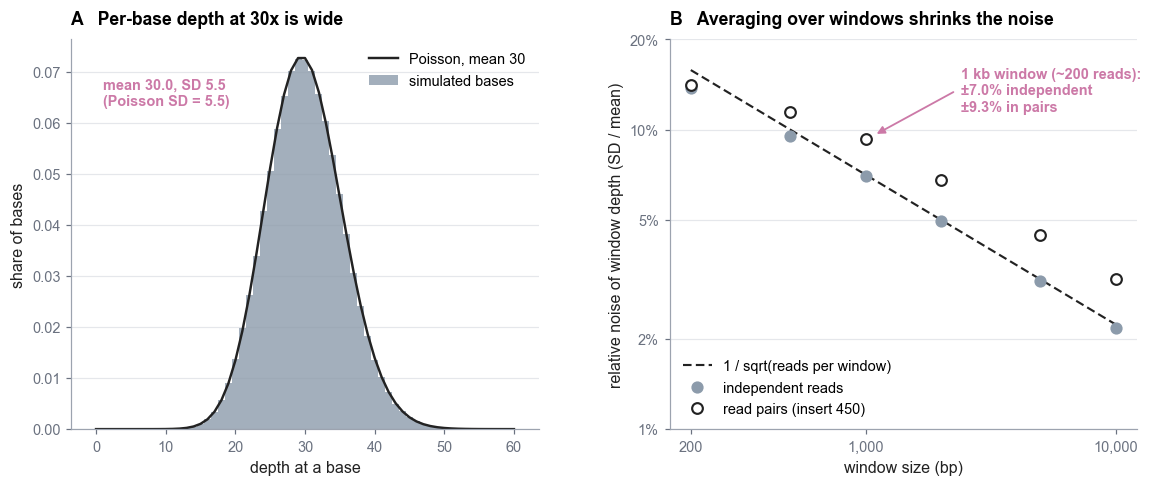

In [14]:
d, sizes, cv_ind, cv_pair, lam = draw_depth_noise(depth=30)

**그림에서 볼 것**
- A: 30x 로 뿌린 장난감 read 의 염기별 깊이 분포(회청 막대)가 Poisson(검은 선)과 거의 겹칩니다. 평균 30 인데 20~40 이 흔합니다.
- B: 창을 크게 잡을수록 창 평균 깊이의 상대 흔들림(표준편차 ÷ 평균)이 줄어듭니다. 독립 read(회청 점)는 점선 $1/\sqrt{\lambda}$ 근처에 놓이고, 짝 read(흰 점)는 그보다 1.3 배쯤 위에 있습니다. 1 kb 창에서 각각 약 ±7%, ±9% 입니다.

**식과 근거**: read 시작점이 서로 독립이고 균일하면 한 염기가 읽히는 횟수는 Poisson 분포를 따릅니다 [8]. 창 평균 깊이의 잡음이 $1/\sqrt{\lambda}$ 꼴이라는 것과 짝 read 의 약 ±9% 는 **이 노트북의 시뮬레이션 결과**이며, 자리 효과가 없는 경우라 실제 데이터의 잡음보다 작습니다.

**직접 바꿔 보기**: `draw_depth_noise(depth=100)` 으로 깊이를 올려 보세요. 1 kb 창 잡음이 얼마로 줄어드나요?

In [15]:
i = list(sizes).index(1000)
print(f"1 kb 창 상대 잡음: 독립 read {cv_ind[i]:.3f}, 짝 read {cv_pair[i]:.3f}, 이론(독립) {1 / np.sqrt(200):.3f}")
assert abs(d.mean() - 30) < 0.5 and abs(d.std() - np.sqrt(30)) < 0.6
assert abs(cv_ind[i] - 1 / np.sqrt(200)) < 0.01
assert cv_pair[i] > 1.15 * cv_ind[i]

1 kb 창 상대 잡음: 독립 read 0.070, 짝 read 0.093, 이론(독립) 0.071


## 7. 핵심: 깊이로 copy 수를 세는 원리, 그리고 자리 효과를 지우는 법

**한 줄 정의**: 종양 시료의 깊이는 그 자리 **DNA 양 $p \cdot CN + 2(1-p)$** 에 비례합니다. 다만 깊이에는 copy 수와 상관없는 **자리 효과**(GC 함량, 정렬 가능성)가 섞여 있어, 그것을 지워야 copy 수 차이만 남습니다.

**왜 필요한가**: 정렬이 어려운 자리(mappability 가 낮은 자리)나 GC 가 극단적인 자리는 copy 수와 상관없이 read 가 적게 쌓입니다. 자리 효과를 지우는 생각은 크게 둘입니다.
- (가) **같은 사람의 정상 시료로 나누기.** 정렬 가능성처럼 **서열이 정하는 효과**는 정상 시료에도 같은 자리에서 똑같이 나타나므로 나누면 지워집니다. Sequenza 같은 도구는 종양 ÷ 정상 깊이 비를 씁니다 [21].
  다만 GC 편향은 시료(library)마다 다르므로 [20], 나누기만으로는 다 지워지지 않습니다.
- (나) **COBALT 와 PURPLE 의 방법.** COBALT 는 종양과 정상 시료를 **따로** 보정합니다. 창마다 깊이를 **같은 시료 안에서** 같은 GC 함량 창들의 중앙값으로 나누고, 정렬 가능성이 낮거나 GC 가 극단적인 창은 뺍니다 [10].
  PURPLE 은 copy 수를 **종양의 GC 보정 비(tumour GC ratio) 하나로** 맞춥니다 [16]. 정상 시료의 비는 정상 쪽 copy 상태 판정(0.85~1.15 면 DIPLOID 등) [13]과, 구간을 다듬을 때 정상 비로 보정한 CN 을 함께 볼 때 씁니다 [16].

**숫자로 따라가기** (purity 0.6, 같은 길이 세 구간의 CN 1, 2, 3)

| 구간 CN | 종양 시료 DNA $0.6 \cdot CN + 0.8$ | 전체 평균(2.0)으로 나눈 기대 깊이 비 |
|---|---|---|
| 1 | 1.4 | 0.70 |
| 2 | 2.0 | 1.00 |
| 3 | 2.6 | 1.30 |

copy 하나 차이가 깊이 비 0.30 차이입니다. purity 가 1 이었다면 0.50 차이였을 것입니다. **purity 가 낮을수록 copy 하나의 차이가 작게 보입니다**(B1 §7, B3 의 출발점).
전체 평균 DNA 는 종양 세포의 평균 copy 수(**ploidy**)에 따라 달라지므로, 깊이 비 1.0 이 CN 2 라는 보장은 없습니다. 이것을 맞추는 값이 B1 §4 의 **normFactor** 입니다.

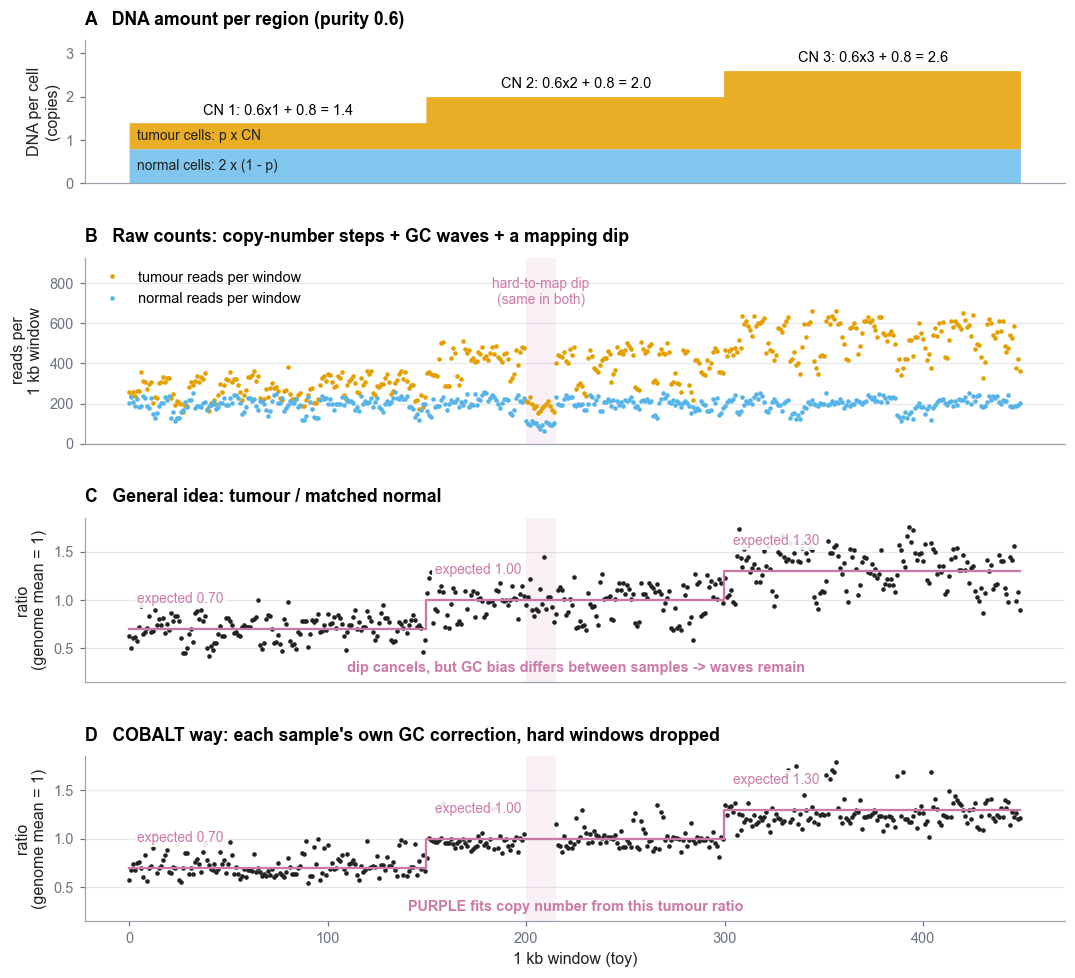

In [16]:
r = depth_ratio_demo(purity=0.6)
draw_depth_counts_copies(r)

**그림에서 볼 것**
- A: 세 구간의 세포당 DNA 양입니다. 정상 몫(하늘, 늘 0.8)은 같고 종양 몫(주황)만 CN 에 따라 0.6 씩 늘어납니다.
- B: 1 kb 창마다 센 read 수입니다. 종양(주황)은 CN 계단을 따르지만 GC 때문에 물결치고, 두 시료 모두 같은 자리(옅은 자주 배경)에서 움푹합니다(정렬이 어려운 자리를 흉내 냄).
  이 장난감은 종양과 정상 library 의 GC 반응을 일부러 다르게 했습니다(실제로도 시료마다 다름 [20]).
- C: (가) 종양 ÷ 정상. 움푹한 자리는 지워지지만, 두 시료의 GC 반응이 달라 물결이 남습니다.
- D: (나) COBALT 식 장난감. 정렬이 어려운 창을 빼고(빈 자리), 종양만 같은 GC 창끼리의 중앙값으로 나눴습니다. 물결이 거의 사라지고 기대값 0.70, 1.00, 1.30 의 계단(자주 선)이 남습니다. PURPLE 이 copy 수를 맞추는 것은 이런 종양 비입니다.

**식과 근거**: 깊이 비 = $\dfrac{p \cdot CN + 2(1-p)}{\text{평균 DNA}}$ (`PurityAdjuster.java` [16]).
PURPLE 은 구간마다 종양 GC ratio 의 중앙값으로 copy 수를 계산하고(`RegionFitCalculator.java` 의 `impliedCopyNumber`), 정상 비는 따로 평균을 내 정상 쪽 상태 판정에 씁니다(`ObservedRegionFactory.java`) [16].
COBALT v2.0 은 같은 GC 창의 중앙값으로 나누는 보정을 시료마다 하고, 정상 시료에는 Mb 규모 GC 편향을 지우는 **이배체 보정**(10 Mb 창마다 비의 중앙값이 이배체라고 보고 맞춤)을 더합니다 [10].
이 그림의 GC 반응 곡선, 움푹한 자리, GC 구간 폭(0.01)은 **이 노트북의 장난감 가정**입니다.

**직접 바꿔 보기**: `draw_depth_counts_copies(depth_ratio_demo(purity=0.2))` 로 바꿔 그려 보세요. 계단 높이 차이가 얼마로 줄어드나요?

In [17]:
lv = [pm.relative_dna(0.6, c) / 2.0 for c in (1, 2, 3)]
assert np.allclose(lv, [0.7, 1.0, 1.3])
k = r["keep"]; d0, d1 = r["dip"]
wave_tn = np.corrcoef(r["ratio_tn"][k] / r["level"][k], r["gc"][k])[0, 1]
wave_cb = np.corrcoef(r["gcr"][k] / r["level"][k], r["gc"][k])[0, 1]
steps = [np.nanmean(r["gcr"][r["cn"] == c]) for c in (1, 2, 3)]
dip_tn = r["ratio_tn"][d0:d1].mean() / r["ratio_tn"][150:200].mean()   # 같은 CN 2 구간 안에서 비교
print(f"GC 와 남은 물결의 상관: 종양÷정상 {wave_tn:.2f}, COBALT 식 {wave_cb:.2f}")
print("COBALT 식 계단:", np.round(steps, 2), " 기대:", lv)
print(f"종양÷정상 에서 움푹한 자리 / 평평한 자리 = {dip_tn:.2f}")
assert abs(wave_tn) > 0.5 and abs(wave_cb) < abs(wave_tn) / 2
assert np.allclose(steps, lv, atol=0.05)
assert abs(dip_tn - 1) < 0.15 and np.isnan(r["gcr"][d0:d1]).all()

GC 와 남은 물결의 상관: 종양÷정상 -0.78, COBALT 식 -0.08
COBALT 식 계단: [0.72 1.   1.28]  기대: [0.7, 1.0, 1.2999999999999998]
종양÷정상 에서 움푹한 자리 / 평평한 자리 = 0.99


## 8. 이형접합 SNP 에서 allele 세기: BAF

**한 줄 정의**: 부모에게서 서로 다른 염기를 하나씩 받은 자리(**이형접합 SNP**)에서, read 중 한쪽 염기(B allele)의 비율이 **BAF**(B-allele frequency) 입니다.

**왜 필요한가**: 깊이는 "모두 합쳐 몇 copy" 만 알려 줍니다. 두 염색체 중 어느 쪽이 늘거나 줄었는지(**major·minor**, 많은 쪽과 적은 쪽 copy 수)는 BAF 가 알려 줍니다.
예를 들어 CN 2 라도 1 + 1(균형)인지 2 + 0(한쪽을 잃은 **LOH**, loss of heterozygosity)인지는 깊이로는 같고 BAF 로만 갈립니다.

**숫자로 따라가기** (read 30개가 덮는 SNP, B 가 많은 쪽 allele)

| 상태(major + minor) | 순수 종양 BAF | purity 0.6 BAF |
|---|---|---|
| 1 + 1 균형 | 1/2 = 0.50 | 0.50 |
| 2 + 1 증폭 | 2/3 = 0.67 | (0.6×2 + 0.4)/(0.6×3 + 0.8) = 0.62 |
| 1 + 0 LOH | 1/1 = 1.00 | (0.6×1 + 0.4)/(0.6×1 + 0.8) = 0.71 |

정상 세포는 늘 1 + 1 이라 B allele 을 0.4 × 1 만큼 보탭니다. 그래서 purity 가 낮을수록 BAF 가 0.5 쪽으로 끌려옵니다.

**AMBER 가 SNP 자리를 고르는 법** [12]: gnomAD(여러 인구 집단에서 모은 사람 유전 변이 빈도 자료) v3 에서 인구 빈도 0.05~0.95 인 SNP 자리 목록을 쓰고, **정상 시료**에서 allele 비율이 0.4~0.65 이며 깊이가 정상 시료 중앙값의 0.5~1.5 배인 자리만 이형접합으로 봅니다. 그 자리에서 종양 시료의 BAF 를 잽니다.
정상 시료로 고르는 이유는, 종양에서는 LOH 때문에 이형접합 자리가 동형접합처럼 보일 수 있기 때문입니다(위 표의 1 + 0, 순수 종양 BAF 1.00).

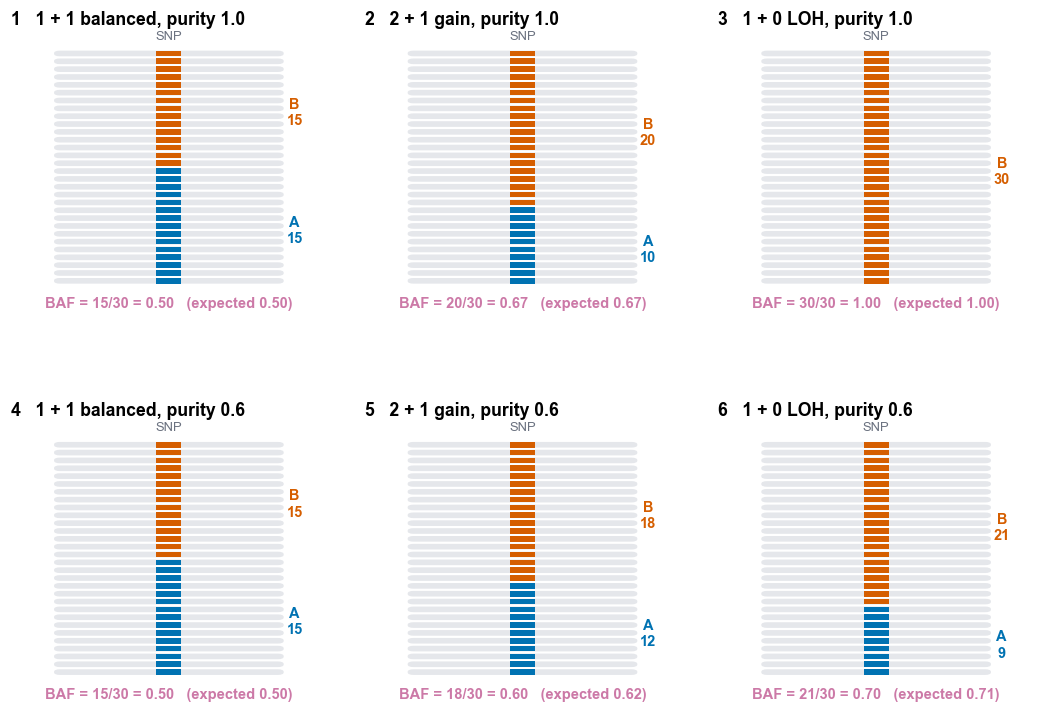

In [18]:
draw_baf_columns()

**그림에서 볼 것**
- 한 칸이 SNP 하나를 덮은 read 30개입니다(회색 막대). 가운데 칸이 SNP 자리 염기로, 빨강이 B, 파랑이 A 입니다. 세기 쉽도록 염기 순서로 정렬했습니다.
- 위 줄(순수 종양): 균형 0.50, 증폭 0.67, LOH 1.00 으로 확실히 갈립니다.
- 아래 줄(purity 0.6): 정상 세포의 A·B 가 섞여 0.50, 0.60, 0.70 으로 0.5 쪽에 모입니다. 각 칸 아래의 "expected" 는 기대 BAF, 왼쪽 값은 read 30개를 반올림해 센 값입니다.

**식과 근거**: $\text{BAF} = \dfrac{p \cdot \text{major} + (1-p)}{p\,(\text{major} + \text{minor}) + 2(1-p)}$. PURPLE 소스 `PurityAdjuster.expectedFrequency` 와 같은 식이고 [16], 이 노트북은 `purple_mini.expected_baf` 로 씁니다. AMBER 의 자리 선택 기준은 [12].

**직접 바꿔 보기**: purity 0.3 에서 LOH(1 + 0)의 BAF 는 얼마일까요?

In [19]:
for p in (1.0, 0.6, 0.3):
    print(f"purity {p}: 1+1 {pm.expected_baf(p, 1, 1):.2f}, 2+1 {pm.expected_baf(p, 2, 1):.2f}, 1+0 {pm.expected_baf(p, 1, 0):.2f}")
assert np.isclose(pm.expected_baf(0.6, 2, 1), 1.6 / 2.6) and np.isclose(pm.expected_baf(0.6, 1, 0), 1.0 / 1.4)
assert baf_counts(1.0, 2, 1)[0] == 20 and baf_counts(0.6, 1, 0)[0] == 21

purity 1.0: 1+1 0.50, 2+1 0.67, 1+0 1.00
purity 0.6: 1+1 0.50, 2+1 0.62, 1+0 0.71
purity 0.3: 1+1 0.50, 2+1 0.57, 1+0 0.59


## 9. 계산에 끼어드는 WGS read 의 다른 특징

앞에서 본 것 말고도 WGS read 에는 copy 수 계산에 영향을 주는 특징이 넷 있습니다.

| 특징 | 무엇이 문제인가 | 도구가 하는 일 |
|---|---|---|
| 중복 read (§2) | 한 분자를 여러 번 세어 깊이가 부풀려짐 | 중복 표시 read 를 COBALT 가 세지 않음 [11], HMF 는 정렬 뒤 중복 표시 [1] |
| 낮은 MAPQ, 반복 서열 (§4) | 다른 자리 read 가 잘못 쌓이거나 빠짐 | MAPQ 10 미만, secondary·supplementary·unmapped read 를 빼고 셈 [11] |
| mappability(정렬 가능성: read 가 한 곳으로만 정렬될 수 있는 정도) 가 낮은 자리 | 읽혀도 자리를 확정 못 해 깊이가 낮게 나옴 | 평균 mappability 0.85 미만 창을 뺌 [10] |
| GC 함량 | 조각의 GC 가 극단적이면 덜 읽힘 [3] | GC 범위 밖 창을 빼고(v2.0 은 0.2~0.6 [10], v2.1 부터 0.24~0.68 [18]), 시료마다 같은 GC 창끼리의 중앙값으로 나눠 보정 [10] (B1 §5) |

마지막으로, read 짝은 **구조 변이(SV)** 를 알려 주는 단서이기도 합니다.

**한 줄 정의**: 종양에서 큰 조각이 빠지거나 옮겨 붙으면, 그 이음매(breakpoint)를 걸친 read 짝은 기준 유전체 위에서 **너무 멀리 떨어져** 놓이고(**discordant pair**, 어긋난 짝), 이음매를 가로지르는 read 는 **두 동강으로 나뉘어** 정렬됩니다(**split read**).

**왜 필요한가**: 깊이만으로는 copy 수가 바뀌는 자리를 1 kb 창 단위로만 알 수 있습니다. SV 단서는 경계를 **염기 하나 단위로** 알려 줍니다.
PURPLE 은 SV 이음매마다 새 구간을 시작하고, 깊이·BAF 에서 찾은 끊김은 이미 있는 구간 경계(SV 이음매, 염색체 끝 등)에서 창 하나 이상 떨어져 있을 때만 더합니다 [13].

**숫자로 따라가기** (종양에서 3 kb 결손, 조각 450 염기)

| | 종양 유전체 위 | 기준 유전체 위 |
|---|---|---|
| 두 read 바깥 끝 사이 거리 | 450 (정상) | 450 + 3,000 = 3,450 (너무 멂) |

결손은 insert size 분포의 먼 끝에 있는, 방향은 정상인 짝으로 드러납니다 [14].

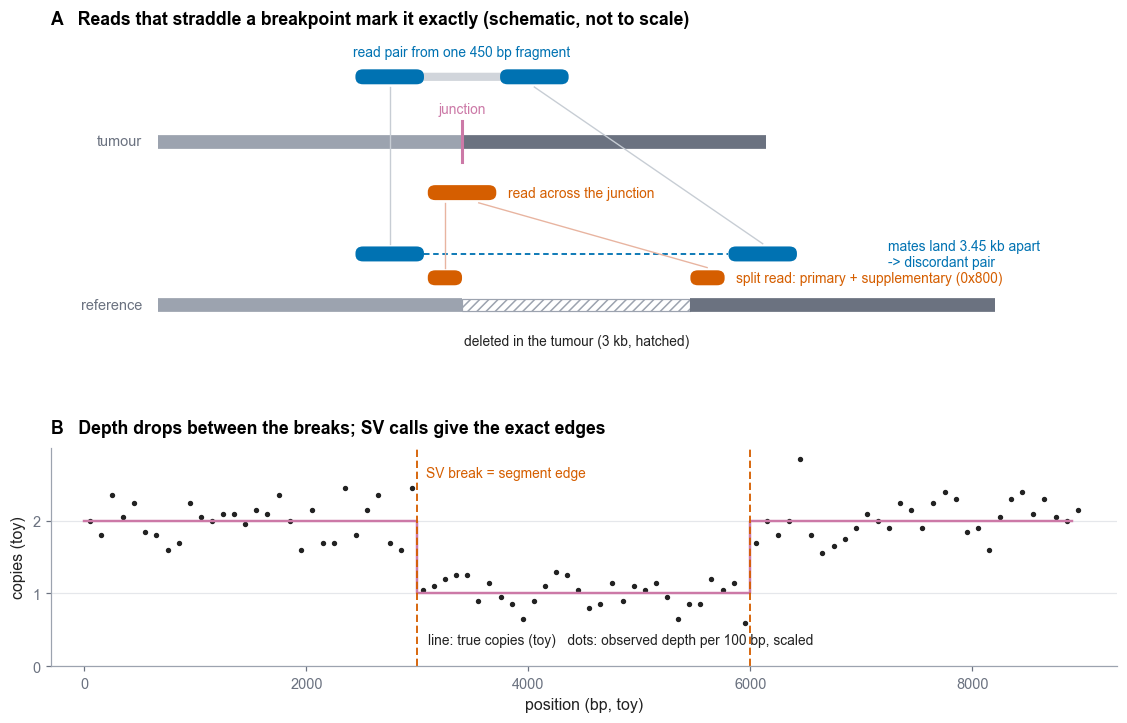

In [20]:
draw_sv_evidence()

**그림에서 볼 것**
- A: 위 줄이 종양 유전체, 아래 줄이 기준 유전체입니다(축척은 무시한 도식). 기준 유전체 가운데 3 kb(빗금)가 종양에서 빠져, 종양에서는 왼쪽과 오른쪽이 바로 붙어 있습니다(자주 눈금이 이음매).
  이음매를 걸친 450 염기 조각의 짝(파랑)을 기준 유전체에 놓으면 두 read 가 3.45 kb 떨어져(파랑 점선) 어긋난 짝이 됩니다.
  이음매를 가로지른 read(빨강)는 기준 유전체에서 두 조각으로 나뉘어, 한쪽은 대표 정렬(primary), 다른 쪽은 supplementary(`0x800`)가 됩니다 [6][7]. 가는 선은 각 read 가 어디로 가는지 이어 줍니다.
- B: 같은 자리의 깊이(점)는 결손 구간에서 2 copy 에서 1 copy 로 떨어집니다. 자주 선은 장난감의 진짜 copy 수, 빨간 점선(SV 이음매)은 구간 경계입니다.

**식과 근거**: DELLY 는 짝 read 와 split read 를 함께 써서 결손, 중복, 역위, 전좌를 찾습니다 [14]. PURPLE 은 SV 이음매를 구간 경계로 쓰고, 품질 좋은 SV 입력이 있으면 copy 수 변화를 염기 단위로 맞출 수 있다고 적습니다 [13].

**직접 바꿔 보기**: 결손이 300 염기라면 어긋난 짝의 거리(750)가 insert size 분포(평균 450, 표준편차 75)에서 얼마나 튈까요? 아래 셀에서 표준편차 몇 개만큼인지 계산합니다.

In [21]:
for deletion in (300, 3000):
    apparent = 450 + deletion
    print(f"결손 {deletion:>4} 염기 → 보이는 거리 {apparent}, 평균에서 표준편차 {(apparent - 450) / 75:.1f}개만큼 멂")

결손  300 염기 → 보이는 거리 750, 평균에서 표준편차 4.0개만큼 멂
결손 3000 염기 → 보이는 거리 3450, 평균에서 표준편차 40.0개만큼 멂


## 10. COBALT 와 AMBER 가 read 에서 만드는 것

**한 줄 정의**: COBALT 는 1 kb 창마다 **평균 깊이**(창에 정렬된 염기 수 ÷ 1,000)를 종양과 정상 시료에서 **따로** 재고, 시료마다 자기 GC 보정을 해 **GC ratio** 를 만듭니다. AMBER 는 이형접합 SNP 마다 B allele 을 세어 BAF 를 만듭니다.

**왜 필요한가**: 이 단계에서 수십억 개의 read 가 창 약 300만 개의 비와 SNP 자리의 BAF 로 줄어듭니다.
PURPLE 의 **주 입력은 이 두 숫자**이고, 여기에 SV 와 체세포 변이가 더해집니다. SV 는 구간 경계에(§9), 체세포 변이는 purity 확인에(B3) 쓰입니다 [13].
PURPLE 은 구간마다 종양 GC ratio 로 copy 수를 맞추고, 정상 시료의 비로는 정상 쪽 copy 상태(예: 0.85~1.15 면 DIPLOID)를 정합니다 [13][16].

**COBALT 가 깊이를 재는 법** (설명서와 코드가 다른 곳이 있습니다)
- v1.16(2024-02)부터 read 수 대신 평균 깊이를 씁니다 [18]. read 의 정렬 조각(alignment block)을 걸치는 창들에 나눠 넣고, 창마다 염기 수를 1,000 으로 나눕니다. v2.0 코드도 같습니다(`ReadDepthAccumulator.java`) [11].
- 그런데 태그 `cobalt-v2.0` 의 README 는 아직 "정렬 시작점을 센다"고 적고 있습니다. 그 README 의 판 기록은 1.14.1 에서 멈춰 있어 코드보다 늦습니다 [10].
- v2.1(2025-07)에서 GC 거르기 범위가 0.2~0.6 에서 0.24~0.68 로 바뀌었습니다 [18].
- 세지 않는 read: MAPQ 10 미만, unmapped, secondary, supplementary, 중복(v2.0 코드 기본값) [11].

**숫자로 따라가기** (순수 종양, 왼쪽 6 kb CN 2(1 + 1), 오른쪽 6 kb CN 3(2 + 1), 정상 시료는 모두 2 copy)

| | 종양 창 깊이 ÷ 종양 평균(2.5) | 정상 창 깊이 ÷ 정상 평균 | 기대 BAF |
|---|---|---|---|
| CN 2 (1 + 1) | 2 / 2.5 = 0.80 | 1.0 (DIPLOID) | 0.50 |
| CN 3 (2 + 1) | 3 / 2.5 = 1.20 | 1.0 (DIPLOID) | 0.67 |

이 장난감에는 GC 효과를 넣지 않았으므로, GC 보정은 "그 시료의 평균으로 나누기"와 같아집니다.

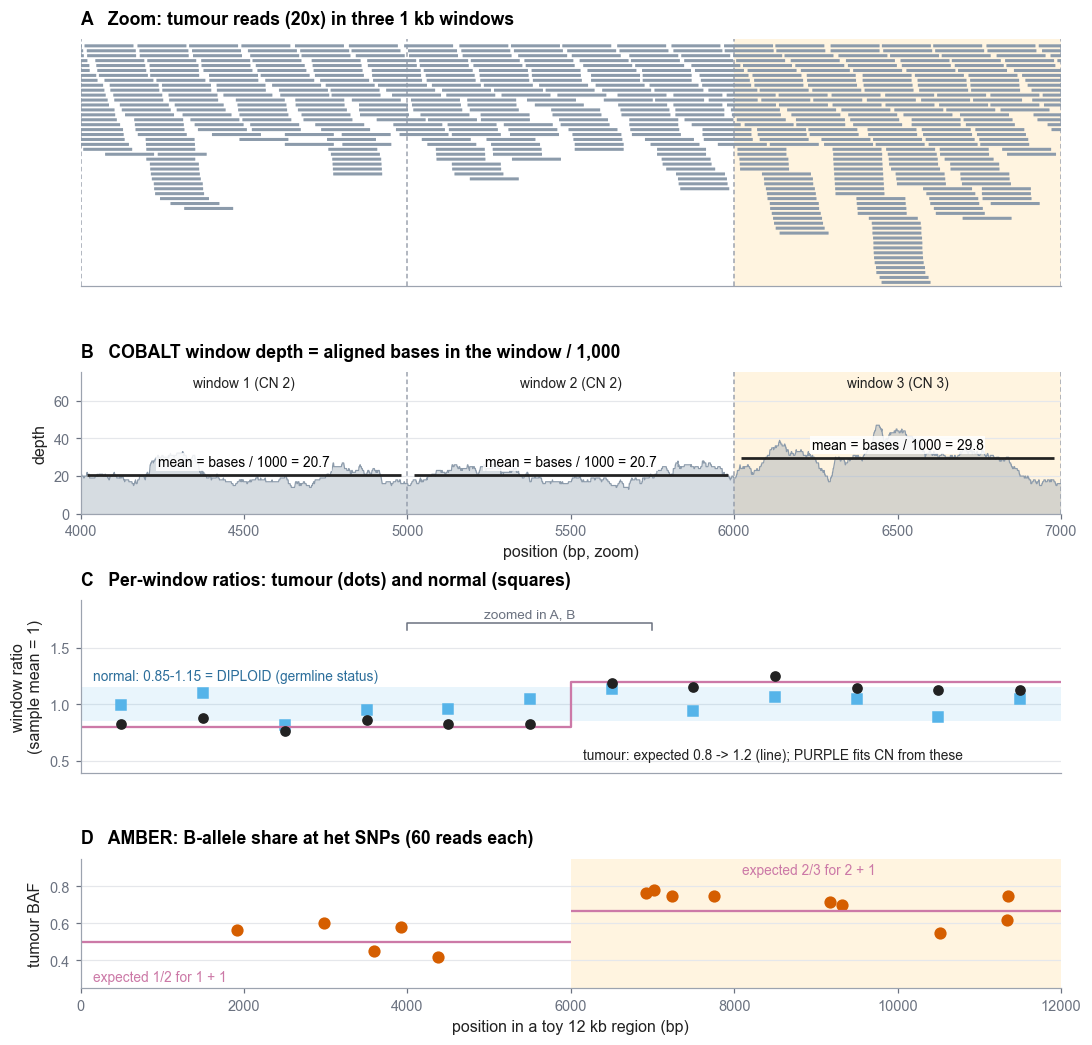

In [22]:
ca = cobalt_amber_demo()
draw_cobalt_amber(ca)

**그림에서 볼 것**
- A: 12 kb 장난감 가운데 3 kb 를 확대한 종양 read(회청, 깊이 20x)와 1 kb 창(세로 점선)입니다. 셋째 창(CN 3, 옅은 주황 배경)이 더 빽빽합니다.
- B: 같은 3 kb 의 자리별 깊이(회청)와 창마다의 평균 깊이(검은 가로선)입니다. COBALT 가 쓰는 값이 이 가로선, 즉 창에 정렬된 염기 수 ÷ 1,000 입니다.
- C: 12 kb 전체의 창별 비입니다. 종양(검은 점)은 기대 계단 0.80 → 1.20(자주 선) 근처에 놓이고, PURPLE 은 이 종양 비로 copy 수를 맞춥니다. 정상(하늘 네모)은 1 근처로 DIPLOID 띠(0.85~1.15, 옅은 하늘) 안에 있습니다. 위쪽 괄호는 A·B 에서 확대한 자리입니다.
  이 장난감은 깊이 20x 에 read 를 하나씩(짝 없이) 뿌려, 창 하나의 비가 ±9% 안팎으로 흔들립니다(§6). 실제 HMF 데이터는 종양 중앙값 106x, 정상 중앙값 38x 였습니다 [1].
- D: AMBER 가 이형접합 SNP 마다 잰 BAF(빨강 점)가 왼쪽 0.5, 오른쪽 2/3 근처에 모입니다. SNP 하나를 read 60개로 재므로 점 하나는 ±0.06 정도 흔들립니다.

**식과 근거**: COBALT v2.0 코드는 정렬 조각을 창에 나눠 넣고 `depth = basesCount / mWindowSize`(창 1,000)로 계산하며, MAPQ 10 이상이고 unmapped·secondary·supplementary·중복이 아닌 read 만 씁니다 [11].
PURPLE 은 깊이 비와 BAF 를 따로 구간으로 나누고(PCF: piecewise constant fit, 값을 평평한 계단 구간들로 나누는 방법), 구간마다 종양 BAF 중앙값, 종양 깊이 비 중앙값, 정상 깊이 비, BAF 점 수를 기록합니다 [13].
정상 깊이 비는 README 에는 중앙값으로 적혀 있지만, v4.1 코드는 평균을 씁니다(`ObservedRegionFactory.java` 의 `referenceMeanRatio`) [16].

**직접 바꿔 보기**: `draw_cobalt_amber(cobalt_amber_demo(depth=60))` 으로 깊이를 올려 다시 그려 보세요. C 의 점이 계단에 얼마나 붙나요?

In [23]:
lv = np.array([2] * 6 + [3] * 6); lv = lv / lv.mean()
assert np.allclose(sorted(set(np.round(lv, 2))), [0.8, 1.2])
# 창 평균 깊이 = 그 창에 겹친 염기 수 ÷ 1,000 (두 방법으로 계산해 같은지 확인)
for kk in (2, 9):
    assert np.isclose(ca["t_win"][kk], bases_in_window(ca["starts"], kk * 1000, (kk + 1) * 1000) / 1000)
left, right = ca["t_ratio"][:6].mean(), ca["t_ratio"][6:].mean()
in_band = ((ca["n_ratio"] >= 0.85) & (ca["n_ratio"] <= 1.15)).mean()
print(f"종양 비 평균: 왼쪽 {left:.2f} (기대 0.80), 오른쪽 {right:.2f} (기대 1.20); 정상 비가 DIPLOID 띠 안인 창 {in_band:.0%}")
assert right > left and abs(left - 0.8) < 0.1 and abs(right - 1.2) < 0.1 and in_band >= 0.75

종양 비 평균: 왼쪽 0.83 (기대 0.80), 오른쪽 1.17 (기대 1.20); 정상 비가 DIPLOID 띠 안인 창 92%


## 연습 문제

1. 유전체 31억 염기를 2 × 150 짝으로 40x 읽으려면 짝이 몇 개 필요할까요?
2. Q 20 인 염기 1,000 개를 읽으면 평균 몇 개가 틀릴까요? FASTQ 에서 Q 20 은 어떤 글자일까요?
3. 깊이 60x, 150 염기 read 에서 1 kb 창의 평균 read 수와, read 가 서로 독립일 때의 상대 잡음은?
4. purity 0.6 에서 CN 1 구간과 CN 2 구간의 종양 깊이 비(CN 1 ÷ CN 2)는?
5. purity 0.6 에서 3 + 1 상태의 BAF 는?
6. 정상 시료에서 BAF 0.7 이 나온 SNP 자리를 AMBER 는 이형접합으로 쓸까요?

<details><summary>정답 보기</summary>

1. $40 \times 3.1\times10^9 / 300 \approx 4.1$억 짝.
2. $1000 \times 10^{-2} = 10$ 개. 글자는 ASCII $20 + 33 = 53$, 즉 `5`.
3. $\lambda = 60 \times 1000 / 150 = 400$, 상대 잡음 $1/\sqrt{400} = 5\%$. 짝 read 를 생각하면 이보다 큽니다(§6 시뮬레이션에서 약 1.3 배).
4. $(0.6 + 0.8) / (1.2 + 0.8) = 1.4 / 2.0 = 0.70$.
5. $(0.6 \times 3 + 0.4) / (0.6 \times 4 + 0.8) = 2.2 / 3.2 \approx 0.69$.
6. 쓰지 않습니다. AMBER 는 정상 시료 allele 비율 0.4~0.65 인 자리만 이형접합으로 봅니다 [12].

</details>

In [24]:
assert round(40 * 3.1e9 / 300 / 1e8, 1) == 4.1
assert chr(20 + 33) == "5" and np.isclose(1000 * 10 ** (-2), 10)
assert np.isclose(1 / np.sqrt(60 * 1000 / 150), 0.05)
assert np.isclose(pm.relative_dna(0.6, 1) / pm.relative_dna(0.6, 2), 0.7)
assert np.isclose(pm.expected_baf(0.6, 3, 1), 2.2 / 3.2)

## 정리

- 조직 DNA 는 모든 세포의 모든 copy 가 섞인 것이고, 조각은 DNA 양에 비례해 나옵니다. 정렬은 조각을 제자리에 돌려놓으므로 **쌓인 높이(깊이)가 그 자리 DNA 양을 따라갑니다.**
- 종양 시료의 DNA 양은 $p \cdot CN + 2(1-p)$ 입니다. 정상 세포가 섞이면 copy 하나의 차이가 $p$ 배로 작아 보입니다.
- 깊이는 무작위 뽑기 때문에 흔들려, COBALT 는 1 kb 창의 평균 깊이를 씁니다(30x 에서 독립 read 가정 약 ±7%, 짝 read 를 고려하면 약 ±9%, 이 노트북의 시뮬레이션). 실제 데이터는 GC 와 mappability 때문에 더 흔들립니다.
- 깊이에는 GC·정렬 가능성 같은 자리 효과가 섞입니다. 정상 시료로 나누면 서열이 정하는 효과는 지워지지만 GC 편향은 시료마다 달라 남습니다.
  COBALT 는 시료마다 자기 GC 보정을 하고 어려운 창을 빼며, PURPLE 은 copy 수를 **종양 GC ratio** 로 맞추고 정상 시료의 비는 정상 쪽 copy 상태 판정에 씁니다.
- 이형접합 SNP 에서 B allele 비율(BAF)은 major·minor 를 알려 줍니다. AMBER 는 정상 시료로 이형접합 자리를 고르고 종양 BAF 를 잽니다.
- 중복, 낮은 MAPQ, 반복 서열, GC 는 걸러 내거나 보정합니다. 어긋난 짝과 split read 는 SV 이음매를 염기 단위로 알려 주고, PURPLE 은 이것을 구간 경계로 씁니다.
- PURPLE 의 주 입력은 COBALT 깊이 비와 AMBER BAF 이고, SV 와 체세포 변이가 구간 경계와 purity 확인에 더해집니다.

다음 노트북(B1)은 깊이 비와 BAF 가 purity·ploidy·CN 에 따라 어떻게 정해지는지를 식으로 다룹니다.

## 출처

모두 2026-11-14 에 직접 열어 확인했습니다. 5 번은 초록, 9 번은 서지 정보만 확인했습니다.

1. **Priestley P, et al.** (2019) Pan-cancer whole-genome analyses of metastatic solid tumours. *Nature* 575:210–216. https://doi.org/10.1038/s41586-019-1689-y (본문: PMC6872491)
   — 이 노트북에서: 종양 중앙값 106x·정상(혈액) 중앙값 38x(초록), DNA 를 평균 450 nt 로 잘라 TruSeq Nano LT library, HiSeq X 에서 2 × 150 짝 읽기, BWA-mem 정렬, 중복 표시 후 거름(Methods).
2. **Bentley DR, et al.** (2008) Accurate whole human genome sequencing using reversible terminator chemistry. *Nature* 456:53–59. https://doi.org/10.1038/nature07517
   — 유리판(flowcell)에 붙인 조각을 그 자리에서 불려 cluster 를 만들고 읽는 방식, 짝 읽기(paired read).
3. **Aird D, et al.** (2011) Analyzing and minimizing PCR amplification bias in Illumina sequencing libraries. *Genome Biol* 12:R18. https://doi.org/10.1186/gb-2011-12-2-r18
   — 염기 조성이 극단적인 자리가 적게 읽히고, library 준비 중 PCR 이 주된 원인(초록).
4. **Cock PJA, et al.** (2010) The Sanger FASTQ file format for sequences with quality scores, and the Solexa/Illumina FASTQ variants. *Nucleic Acids Res* 38:1767–1771. https://doi.org/10.1093/nar/gkp1137
   — 서열 줄은 여러 줄로 나눌 수 있으나 OBF 도구는 나누지 않아 read 하나 = 네 줄, Sanger FASTQ 는 ASCII 33~126 으로 PHRED 0~93 을 적고 이는 틀릴 확률 1.0~$10^{-9.3}$.
5. **Ewing B, Green P** (1998) Base-calling of automated sequencer traces using phred. II. Error probabilities. *Genome Res* 8:186–194. https://doi.org/10.1101/gr.8.3.186
   — phred 가 염기마다 틀릴 확률을 추정한다는 것(초록). 본문은 로그인이 필요해 열지 못했습니다.
6. **SAM/BAM 형식 명세** (hts-specs SAMv1, 2025-08-12 판, 저장소 버전 b5341fb). https://samtools.github.io/hts-specs/SAMv1.pdf
   — MAPQ = −10 log10 Pr{mapping position is wrong}, 여러 자리 정렬은 주로 반복 서열 때문이고 read 가 길수록 드묾, flag `0x4`·`0x100`·`0x400`(PCR or optical duplicate)·`0x800`(supplementary), chimeric 정렬의 정의.
7. **Li H** (2013) Aligning sequence reads, clone sequences and assembly contigs with BWA-MEM. arXiv:1303.3997. https://arxiv.org/abs/1303.3997
   — 짝 read 지원과 chimeric 정렬(초록).
8. **Illumina Technical Note: Estimating Sequencing Coverage** (Pub. No. 770-2011-022). https://www.illumina.com/documents/products/technotes/technote_coverage_calculation.pdf
   — Lander/Waterman 식 $C = LN/G$($G$ 는 반수체 유전체 길이, 예시 $3 \times 10^9$), 한 염기가 읽히는 횟수가 Poisson 분포를 따른다는 결론.
9. **Lander ES, Waterman MS** (1988) Genomic mapping by fingerprinting random clones: a mathematical analysis. *Genomics* 2:231–239. https://doi.org/10.1016/0888-7543(88)90007-9
   — 8 번이 인용하는 원 논문. 서지 정보와 초록만 확인했습니다.
10. **COBALT README**, 태그 `cobalt-v2.0`. https://github.com/hartwigmedical/hmftools/blob/cobalt-v2.0/cobalt/README.md
    — GC 0.2~0.6 밖·평균 mappability 0.85 미만 창 제외, 같은 GC 창의 중앙값으로 나누는 GC 보정(시료마다), 정상 시료의 이배체 보정(10 Mb 창의 중앙값을 이배체로 봄).
    주의: 이 README 의 "정렬 시작점을 센다"는 설명과 판 기록(1.14.1 까지)은 코드보다 늦습니다. 깊이 계산은 11 번 코드와 18 번 릴리스 노트를 따랐습니다.
11. **COBALT 소스**, 태그 `cobalt-v2.0`. https://github.com/hartwigmedical/hmftools/tree/cobalt-v2.0/cobalt
    — `count/ReadDepthAccumulator.java`("accumulate read alignment blocks and calculate read depth per 1000 base windows", `depth = basesCount / mWindowSize`), `count/BamReadCounter.java`(정렬 조각을 창에 나눠 넣음, 중복 read 제외), `CobaltConstants.java`(창 1,000, 기본 최소 MAPQ 10), `hmf-common/.../bam/BamSlicerFilter.java`(MAPQ·unmapped·secondary 거르기).
12. **AMBER README**, 태그 `amber-v4.1`. https://github.com/hartwigmedical/hmftools/blob/amber-v4.1/amber/README.md
    — gnomAD v3 SNP 자리(인구 빈도 0.05~0.95), 이형접합 판정(정상 allele 비율 0.4~0.65, 깊이 중앙값의 0.5~1.5 배), 최소 염기 품질 13.
13. **PURPLE README**, 태그 `purple-v4.1`. https://github.com/hartwigmedical/hmftools/blob/purple-v4.1/purple/README.md
    — 첫 문단: BAF(AMBER), 깊이 비(COBALT), 체세포 변이, 구조 변이를 합쳐 purity 와 copy 수를 추정. 2. Segmentation: 깊이 비와 BAF 를 따로 PCF, SV 이음매마다 새 구간, 깊이·BAF 끊김은 기존 구간 경계에서 창 하나 이상 떨어질 때만 더함, 구간마다 BAF·깊이 비와 BAF 점 수, 정상 쪽 copy 상태(DIPLOID 0.85~1.15 등). Input: SV 입력이 copy 수 변화를 염기 단위로 맞춰 줌.
    README 는 정상 깊이 비도 중앙값이라고 적지만, v4.1 코드는 평균을 씁니다(16 번).
14. **Rausch T, et al.** (2012) DELLY: structural variant discovery by integrated paired-end and split-read analysis. *Bioinformatics* 28:i333–i339. https://doi.org/10.1093/bioinformatics/bts378
    — 짝 read 와 split read 를 함께 써서 SV 를 찾음, 결손은 insert size 분포 먼 끝의 정상 방향 짝으로 드러남.
15. **Ensembl REST API**, `info/assembly/homo_sapiens`. https://rest.ensembl.org/info/assembly/homo_sapiens?content-type=application/json
    — GRCh38.p14 golden path 3,099,750,718 bp. 염색체 25 개(chrY 57,227,415 bp 포함) 외에 위치 미정 조각 약 1,150 만 bp 를 포함한 합.
16. **PURPLE 소스**, 태그 `purple-v4.1`. https://github.com/hartwigmedical/hmftools/tree/purple-v4.1/purple
    — `fitting/PurityAdjuster.java`(`totalObservations = purity × tumorCopyNumber + normalCopyNumber × (1 − purity)`, 정상이 2 copy 면 $p \cdot CN + 2(1-p)$; `expectedFrequency` 109~122 줄: 기대 BAF), `fitting/RegionFitCalculator.java`(85 줄 근처: `impliedCopyNumber` 를 종양 비로만 계산, `refNormalisedCopyNumber` 는 정상 비로 보정), `region/ObservedRegionFactory.java`(123~124 줄: 종양 비는 `tumorMedianRatio`, 정상 비는 `referenceMeanRatio`; 405~407 줄: 종양은 `tumorGCRatio`, 정상은 `referenceGCDiploidRatio`).
17. **Picard MarkDuplicates 소스** (broadinstitute/picard, master). https://github.com/broadinstitute/picard/blob/master/src/main/java/picard/sam/markduplicates/MarkDuplicates.java
    — "works by comparing sequences in the 5 prime positions of both reads and read-pairs".
18. **COBALT 릴리스 노트**: v1.16 (2024-02-05) https://github.com/hartwigmedical/hmftools/releases/tag/cobalt-v1.16 , v2.0 (2025-02-16, PURPLE 4.1 과 같은 시기) https://github.com/hartwigmedical/hmftools/releases/tag/cobalt-v2.0 , v2.1 (2025-07-18) https://github.com/hartwigmedical/hmftools/releases/tag/cobalt-v2.1
    — v1.16 "use mean read depths instead of read counts", v2.1 "GC ratio constants changed from 0.2 - 0.6 to 0.24 - 0.68".
19. **BWA 소스** (lh3/bwa, master) `bwamem.c` 의 `mem_approx_mapq_se`. https://github.com/lh3/bwa/blob/master/bwamem.c
    — 987 줄 `if (sub >= a->score) return 0;`: 두 번째로 좋은 점수가 가장 좋은 점수 이상이면 MAPQ 0.
20. **Benjamini Y, Speed TP** (2012) Summarizing and correcting the GC content bias in high-throughput sequencing. *Nucleic Acids Res* 40:e72. https://doi.org/10.1093/nar/gks001
    — GC 편향이 copy 수 신호를 덮을 수 있고, "The bias is not consistent between samples"(초록).
21. **Favero F, et al.** (2015) Sequenza: allele-specific copy number and mutation profiles from tumor sequencing data. *Ann Oncol* 26:64–70. https://doi.org/10.1093/annonc/mdu479
    — 관찰값으로 "the average depth ratio (tumor versus normal)" 와 BAF 를 씀(Methods).

이 노트북의 세포 그림, 조각, 품질 막대, 깊이, 창, GC 반응, BAF, SV 그림의 숫자는 모두 **이 노트북의 장난감 시뮬레이션**이며 실제 데이터의 크기를 뜻하지 않습니다.